#<center> **FUNDAMENTOS DE PROGRAMACIÓN PARA LA CIENCIA DE DATOS E INTELIGENCIA ARTIFICIAL** </center>
## <center> **Especialización Ciencia de Datos e Inteligencia Artificial - ECDIA** </center>
###  <center> Universidad Tecnológica - UTEC </center>
### <center> Instructor: Gonzalo Pérez </center>

# <font color="#00E5FF"> Presentación trabajo final

#**LAST MILE DELIVERY EN SHANGAI**

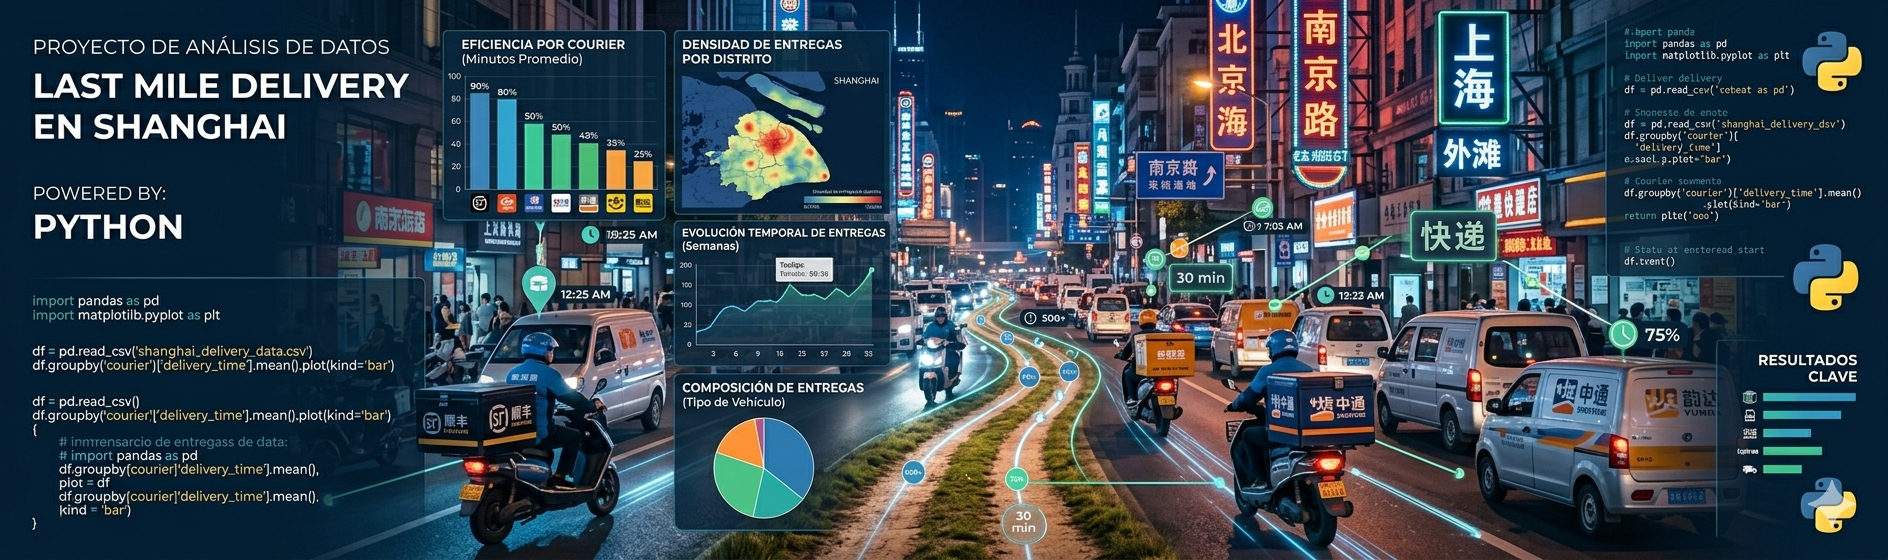

 # <font color="#00E5FF">Contextualización de la Problemática</font>

El presente análisis se centra en la etapa crítica de la logística conocida como **Last Mile Delivery** (entrega de última milla) en la ciudad de **Shanghái**, uno de los nodos comerciales más densos y complejos del mundo. El objetivo principal es desentrañar los factores geográficos y temporales que afectan los tiempos de entrega para optimizar el rendimiento de la flota y garantizar mejores promesas de servicio.

### <font color="#1E88E5">El Dataset</font>

Trabajamos con un robusto conjunto de datos que abarca **6 meses de operaciones**, compuesto por **1.483.864 registros**  organizados en **17 columnas**. Este volumen de información permite un análisis estadísticamente significativo sobre el comportamiento de **1.733 couriers** que operan en **52 regiones** distintas de la ciudad.

La calidad del dataset es excepcional, presentándose en un formato **CSV prolijo y estándar**, sin registros duplicados ni valores nulos. Para garantizar la privacidad, las coordenadas geográficas han sido anonimizadas con un radio de aproximación de 10 metros.

### <font color="#1E88E5">Dimensiones de Análisis</font>

El esquema de datos nos permite abordar el problema desde dos frentes principales:

1.  **Dimensión Temporal:** Analizamos el flujo desde el momento de la aceptación del pedido (`accept_time`) hasta la entrega final (`delivery_time`), permitiendo identificar cuellos de botella en horas pico o tránsito.
2.  **Dimensión Geográfica:** Gracias a la captura de coordenadas GPS en puntos clave (pickup, posición del courier y destino), podemos mapear la eficiencia en diferentes zonas de entrega y regiones (AOI - Area of Interest).

Este enfoque analítico busca transformar datos crudos en estrategias accionables para optimizar los recursos logísticos en el ecosistema del e-commerce actual.

# Extracción de datos

In [ ]:
#BLOQUE 1
#Importamos en esta sección las librerías necesarias
#para procesar los datos en las diferentes etapas.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import folium
from folium.plugins import HeatMap
import geopandas as gpd
from shapely.geometry import Point

In [ ]:
#BLOQUE 2
#Cargamos la información de la base de datos.
def get_my_data():
    url = "https://huggingface.co/datasets/Cainiao-AI/LaDe/resolve/main/delivery/delivery_sh.csv"
    df = pd.read_csv(url)
    return df
df = get_my_data()

In [ ]:
#Corremos funciones para obtener información del dataframe.
df.shape

(1483864, 17)

In [ ]:
#Corremos funciones para obtener información del dataframe.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1483864 entries, 0 to 1483863
Data columns (total 17 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           1483864 non-null  int64  
 1   region_id          1483864 non-null  int64  
 2   city               1483864 non-null  object 
 3   courier_id         1483864 non-null  int64  
 4   lng                1483864 non-null  float64
 5   lat                1483864 non-null  float64
 6   aoi_id             1483864 non-null  int64  
 7   aoi_type           1483864 non-null  int64  
 8   accept_time        1483864 non-null  object 
 9   accept_gps_time    1483864 non-null  object 
 10  accept_gps_lng     1483864 non-null  float64
 11  accept_gps_lat     1483864 non-null  float64
 12  delivery_time      1483864 non-null  object 
 13  delivery_gps_time  1483864 non-null  object 
 14  delivery_gps_lng   1483864 non-null  float64
 15  delivery_gps_lat   1483864 non-n

# <font color="#00E5FF">Validación Técnica del Dataset</font>

Una vez cargado el archivo en un DataFrame de Pandas (`df`), la ejecución de `df.info()` nos proporciona información de los datos. Los que nos permite confirmar:

### <font color="#1E88E5">Hallazgos de Calidad de Datos</font>
* **Ausencia de Valores Nulos:** Se confirma que **no existen valores nulos** en ninguna de las 17 columnas. Esto garantiza que los análisis estadísticos no tendrán sesgos por datos faltantes.

### <font color="#1E88E5">Análisis de la Estructura</font>
La composición de las 17 columnas es la siguiente:

* **Atributos de Identificación y Geográficos:** Columnas como `order_id`, `region_id`, `courier_id`, `aoi_id`, `aoi_type`, y `ds` están cargadas correctamente como **enteros (`int64`)**.
* **Coordenadas GPS de Precisión:** Las columnas de latitud y longitud (como `lat`, `lng`, `accept_gps_lat`, etc.) se registran como **decimales (`float64`)**, lo que permite una alta precisión en el mapeo de rutas.
* **Variables Temporales Críticas:** Las columnas fundamentales para el análisis de tiempos (`accept_time`, `accept_gps_time`, `delivery_time`, `delivery_gps_time`) están actualmente cargadas como **objetos (`object`)**, lo que significa que están como texto. Por lo que debemos convertir estos valores en datetime.







### <font color="#1E88E5">Glosario</font>

A continuación se encuentra una descripción de las columnas del dataset:</font>
<br>
| Categoría | Atributo | Descripción | Unidad/Formato |
| :--- | :--- | :--- | :--- |
| **Identificación Orden** | `order_id` | Identificador único de cada paquete | Id |
| **Información General** | `lng/lat` | Coordenadas de donde el courier acepta el pedido | Float |
| | `city` | Ciudad | String |
| | `region_id` | Id de región | Id |
| | `aoi_id` | Id Área de interés (AOI)| Id |
| | `aoi_type` | Tipo de AOI | Categorical |
| **Información Courier** | `courier_id` | Courier Id | Id |
| **Información Tarea-Evento** | `accept_time` | Fecha_Hora en que el Courier acepta la tarea | Time |
| | `accept_gps_time` | Fecha_Hora del punto GPS más cercano a la hora de aceptación | Time |
| | `accept_gps_lng/lat`| Coordenadas donde esta el paquete | Float |
| | `delivery_time` |  Fecha_Hora cuando el Courier finaliza la entrega.| Time |
| | `delivery_gps_time`| Fecha_Hora del punto GPS más cercano a la hora de entrega" | Time |
| | `delivery_gps_lng/lat`| Coordenadas cuando el Courier finaliza la tarea | Float |
| **Información Contexto** | `ds` | La Fecha de la orden (MMDD) | Date |

In [ ]:
# ----------------- Análisis de DUPLICADOS
# Búsqueda de registros duplicados según order ID.
# Sanidad de la base de datos
total_unicos = df['order_id'].nunique()
total_registros = len(df)

print(f"Valores únicos en order_id: {total_unicos}")
print(f"Total de registros en el DataFrame: {total_registros}")

# Verificación lógica
if total_unicos == total_registros:
    print("¡Confirmado! No hay IDs de orden repetidos. Cada registro es único.")
else:
    print("Atención: Se encontraron IDs duplicados.")

Valores únicos en order_id: 1483864
Total de registros en el DataFrame: 1483864
¡Confirmado! No hay IDs de orden repetidos. Cada registro es único.


In [ ]:
df.head()

,order_id,region_id,city,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_time,accept_gps_lng,accept_gps_lat,delivery_time,delivery_gps_time,delivery_gps_lng,delivery_gps_lat,ds
0,3158819,1,Shanghai,164,121.52128,31.06614,450,1,06-04 11:05:00,06-04 11:05:00,121.52281,31.10598,06-04 17:40:00,06-04 17:40:00,121.52407,31.06614,604
1,751342,1,Shanghai,164,121.52124,31.06687,450,1,06-04 11:18:00,06-04 11:18:00,121.52286,31.10599,06-04 15:06:00,06-04 15:06:00,121.52412,31.06618,604
2,3380476,1,Shanghai,164,121.52106,31.06731,450,1,06-03 10:13:00,06-03 10:13:00,121.52285,31.10591,06-03 15:11:00,06-03 15:11:00,121.52059,31.06672,603
3,2184571,1,Shanghai,164,121.52128,31.06616,450,1,06-04 10:39:00,06-04 10:39:00,121.52282,31.10593,06-04 15:41:00,06-04 15:41:00,121.52280,31.10542,604
4,941371,1,Shanghai,164,121.52123,31.06614,450,1,06-04 11:18:00,06-04 11:18:00,121.52285,31.10593,06-04 14:07:00,06-04 14:07:00,121.52290,31.06758,604


In [ ]:
# De la visualización de las primeras filas parece que las columnas de tiempo
# accept_time y accept_gps_time y delivery_time y delivery_gps_time son iguales. Vamos a verificarlo.

# Creamos una función que verifica si toda la columna es igual a la otra y la usamos en los 2 pares de columnas.
son_iguales_accept = df['accept_time'].equals(df['accept_gps_time'])
son_iguales_delivery = df['delivery_time'].equals(df['delivery_gps_time']) # [cite: 171, 1488]

# El resultado de esta función es un booleano por lo que lo vinculamos con un texto, para naturalizar la respuesta.
txt_accept = "SÍ" if son_iguales_accept else "NO"
txt_delivery = "SÍ" if son_iguales_delivery else "NO"

# Crear y mostrar el texto con los resultados estructurados
mensaje = (
    f"Resultados de la verificación de consistencia:\n"
    f"- ¿Las columnas 'accept_time' y 'accept_gps_time' son exactamente iguales?: {txt_accept}\n"
    f"- ¿Las columnas 'delivery_time' y 'delivery_gps_time' son exactamente iguales?: {txt_delivery}"
)

# Mostrar el mensaje en pantalla
print(mensaje)

Resultados de la verificación de consistencia:
- ¿Las columnas 'accept_time' y 'accept_gps_time' son exactamente iguales?: SÍ
- ¿Las columnas 'delivery_time' y 'delivery_gps_time' son exactamente iguales?: SÍ


In [ ]:
#Generamos un control de existencia de las columnas.
#para evidar que de error al ejecutar 2 veces el códogo.
columns_to_drop = ['accept_gps_time', 'delivery_gps_time']

# Only drop columns that are currently present in the DataFrame
existing_columns = [col for col in columns_to_drop if col in df.columns]

if existing_columns:
    df.drop(columns=existing_columns, inplace=True)
    print(f"Columnas Eliminadas: {existing_columns}")
else:
    print("Las columnas no están actualmente en la tabla")

df.head(1)

Columnas Eliminadas: ['accept_gps_time', 'delivery_gps_time']


,order_id,region_id,city,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_lng,accept_gps_lat,delivery_time,delivery_gps_lng,delivery_gps_lat,ds
0,3158819,1,Shanghai,164,121.52128,31.06614,450,1,06-04 11:05:00,121.52281,31.10598,06-04 17:40:00,121.52407,31.06614,604


In [ ]:
#Verificamos la eliminaciòn de las columnas solicitadas previamente.
# Antes teniamos 17 columnas, y ahora hay 15
df.shape

(1483864, 15)

In [ ]:
# ANALISIS DE CARDINALIDAD
# Obtener la cantidad de valores únicos por cada columna
valores_unicos = df.nunique()

# Mostrar el resultado
print(valores_unicos)

order_id            1483864
region_id                52
city                      1
courier_id             1733
lng                   68747
lat                   56161
aoi_id                15564
aoi_type                 16
accept_time          130836
accept_gps_lng         1233
accept_gps_lat         1252
delivery_time        144334
delivery_gps_lng      73503
delivery_gps_lat      58280
ds                      184
dtype: int64


count    1733.000000
mean      856.240046
std      1378.313167
min         1.000000
1%          1.000000
5%          2.000000
10%         7.000000
25%        28.000000
50%       157.000000
75%       956.000000
90%      3302.800000
99%      5363.720000
max      7336.000000
Name: total_orders, dtype: float64


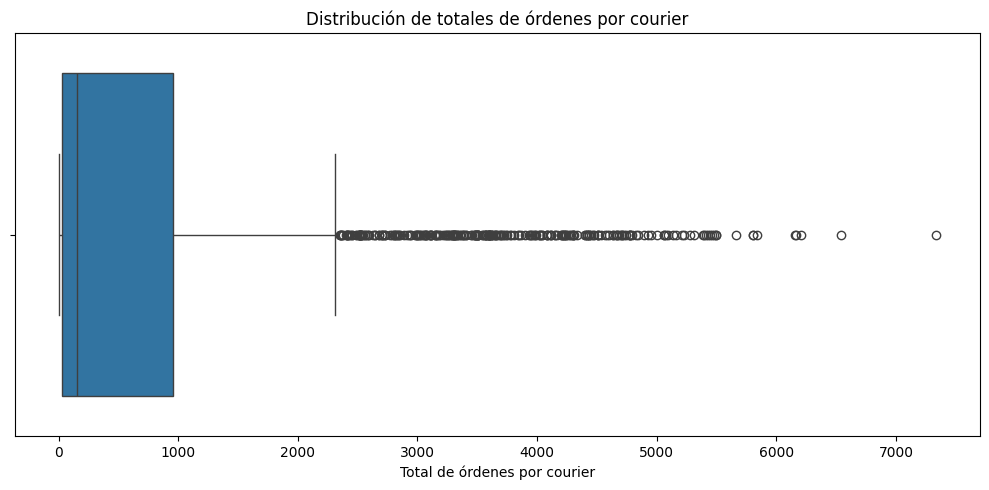

In [ ]:
# ANALISIS DE DISTRIBUCION DE ENTREGAS POR CADA COURIER
# Exploratorio de cantidad de entregas por courier
# Gráfico de caja que agrupe couriers y la cantidad total de ordenes
totals = df.groupby('courier_id').size().reset_index(name='total_orders')

# describe con percentiles
print(totals['total_orders'].describe(percentiles=[.01, .05, .1, .25, .5, .75, .9, .99]))

# boxplot horizontal de la distribución de totales
plt.figure(figsize=(10,5))
sns.boxplot(x='total_orders', data=totals, orient='h')
plt.xlabel('Total de órdenes por courier')
plt.title('Distribución de totales de órdenes por courier')
plt.tight_layout()
plt.show()


In [ ]:
# Lectura de la caja
# Ahi vemos que en general hay muchos outliers, y una distribución muy sesgada. hay que ver que hacemos con eso.
# El 75% de los couriers hizo 1000 órdenes o menos. Mientras que el otro 25% hizo mas de 1 Millon (ya que son 1,4Millones de órdenes.)
# por lo que en los outliers son los más relevantes. Son couries ultra activos, y que nos permite medir sí a los mejores.

In [ ]:
# ---------------------- ANALISIS DE DISTRIBUCION DE ENTREGAS POR CADA COURIER
#Vamos a analizar de otra forma la distribucion de órdenes en funcion de cada courier.
#Hacer una distribución acumulativa inversa basada estrictamente en una cuota fija de volumen.

# 1. Agrupamos por courier y ordenamos de MENOR a MAYOR cantidad de pedidos
pedidos_por_courier = df.groupby('courier_id').size().reset_index(name='cantidad_pedidos')
pedidos_por_courier = pedidos_por_courier.sort_values(by='cantidad_pedidos', ascending=True).reset_index(drop=True)

# 2. Definimos el tamaño exacto de cada uno de los 5 bloques de pedidos
total_pedidos_global = pedidos_por_courier['cantidad_pedidos'].sum()
tamano_bloque = total_pedidos_global / 5

print(f"Total de pedidos en el dataset: {total_pedidos_global:,}")
print(f"Meta de pedidos por cada uno de los 5 bloques: {tamano_bloque:,.1f}\n")

# 3. Calculamos la suma acumulada de pedidos (de menos a más)
pedidos_por_courier['pedidos_acumulados'] = pedidos_por_courier['cantidad_pedidos'].cumsum()

# 4. Asignamos el bloque matemático (0 a 4).
# Restamos 1 unidad a la suma acumulada para evitar que el límite exacto cree un sexto bloque erróneo.
pedidos_por_courier['num_bloque'] = (pedidos_por_courier['pedidos_acumulados'] - 1) // tamano_bloque
pedidos_por_courier['num_bloque'] = pedidos_por_courier['num_bloque'].astype(int).clip(0, 4)

# Mapeamos nombres claros para los 5 grupos
nombres_bloques = {
    0: 'Grupo 1 (Menos pedidos)',
    1: 'Grupo 2',
    2: 'Grupo 3',
    3: 'Grupo 4',
    4: 'Grupo 5 (Más pedidos)'
}
pedidos_por_courier['grupo_pedidos'] = pedidos_por_courier['num_bloque'].map(nombres_bloques)

# 5. Consolidamos el reporte final contando cuántos couriers caen en cada grupo
reporte_final = pedidos_por_courier.groupby('grupo_pedidos', observed=False).agg(
    cantidad_couriers=('courier_id', 'count'),
    pedidos_reales_acumulados=('cantidad_pedidos', 'sum')
).reset_index()

# Calculamos qué porcentaje de la flota total representa cada grupo de couriers
total_couriers = len(pedidos_por_courier)
reporte_final['porcentaje_de_la_flota'] = (reporte_final['cantidad_couriers'] / total_couriers) * 100

print("--- REPORTE DE COURIERS NECESARIOS POR CUOTA DE PEDIDOS ---")
print(reporte_final.to_string(index=False, formatters={
    'cantidad_couriers': '{:,}'.format,
    'pedidos_reales_acumulados': '{:,}'.format,
    'porcentaje_de_la_flota': '{:.2f}%'.format
}))

Total de pedidos en el dataset: 1,483,864
Meta de pedidos por cada uno de los 5 bloques: 296,772.8

--- REPORTE DE COURIERS NECESARIOS POR CUOTA DE PEDIDOS ---
          grupo_pedidos cantidad_couriers pedidos_reales_acumulados porcentaje_de_la_flota
Grupo 1 (Menos pedidos)             1,370                   295,442                 79.05%
                Grupo 2               140                   296,723                  8.08%
                Grupo 3                91                   296,420                  5.25%
                Grupo 4                74                   297,969                  4.27%
  Grupo 5 (Más pedidos)                58                   297,310                  3.35%


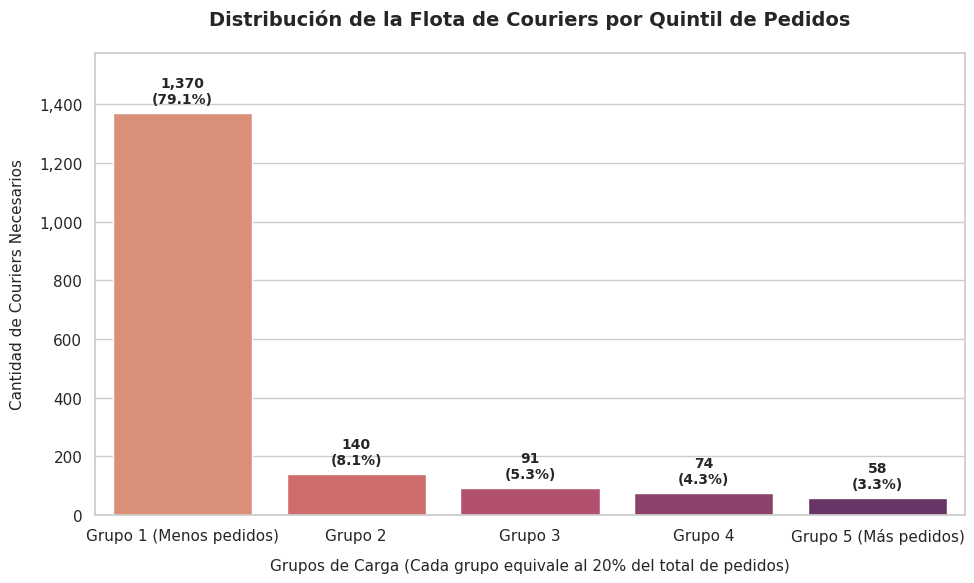

In [ ]:
# ---------------------- ANALISIS DE DISTRIBUCION DE ENTREGAS POR CADA COURIER
# Graficamos los resultados.
# Configuramos estilo y tamaño.
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Creamos un  gráfico de barras verticales, con paleta degradada.
ax = sns.barplot(
    x='grupo_pedidos',
    y='cantidad_couriers',
    data=reporte_final,
    hue='grupo_pedidos',
    palette='flare',
    legend=False
)


# Extraemos los porcentajes en el mismo orden del gráfico para las etiquetas
porcentajes = reporte_final['porcentaje_de_la_flota'].values

for i, bar in enumerate(ax.patches):
    # Obtenemos la altura de la barra (cantidad de couriers)
    altura = bar.get_height()
    if altura > 0:
        ax.annotate(
            f'{altura:,.0f}\n({porcentajes[i]:.1f}%)',
            xy=(bar.get_x() + bar.get_width() / 2, altura),
            xytext=(0, 5),  # 5 puntos de desplazamiento hacia arriba
            textcoords="offset points",
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )

# Agredamos títulos
plt.title('Distribución de la Flota de Couriers por Quintil de Pedidos', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Grupos de Carga (Cada grupo equivale al 20% del total de pedidos)', fontsize=11, labelpad=10)
plt.ylabel('Cantidad de Couriers Necesarios', fontsize=11, labelpad=10)

# Damos un 15% de holgura en el eje Y para que las etiquetas de texto de la barra más alta no se corten
plt.ylim(0, reporte_final['cantidad_couriers'].max() * 1.15)

# Formateamos el eje Y con separadores de miles
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.tight_layout()

# Guardar y mostrar
plt.savefig('distribucion_flota_quintiles.png', dpi=300)
plt.show()

In [ ]:
# ---------------------- ANALISIS DE DISTRIBUCION DE ENTREGAS POR CADA COURIER
# A partir del gáfico anterior detectamos que el 79,1 % de los couriers (ordenados de menor a mayor),
# representan el 20% de los pedidos. Por eso resolvemos eliminarlos.
# Vamos a eliminar a los couriers del grupo 1. Que son muchos couriers pero poco relevantes.

In [ ]:
# Realizamos un LEFT JOIN para mantener todas las filas originales de 'df'
# y traer únicamente la columna 'grupo_pedidos' basada en la coincidencia de 'courier_id'
df = pd.merge(
    df,
    pedidos_por_courier[['courier_id', 'grupo_pedidos']],
    on='courier_id',
    how='left'
)

# Verificamos que la columna se haya agregado correctamente
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1483864 entries, 0 to 1483863
Data columns (total 16 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   order_id          1483864 non-null  int64  
 1   region_id         1483864 non-null  int64  
 2   city              1483864 non-null  object 
 3   courier_id        1483864 non-null  int64  
 4   lng               1483864 non-null  float64
 5   lat               1483864 non-null  float64
 6   aoi_id            1483864 non-null  int64  
 7   aoi_type          1483864 non-null  int64  
 8   accept_time       1483864 non-null  object 
 9   accept_gps_lng    1483864 non-null  float64
 10  accept_gps_lat    1483864 non-null  float64
 11  delivery_time     1483864 non-null  object 
 12  delivery_gps_lng  1483864 non-null  float64
 13  delivery_gps_lat  1483864 non-null  float64
 14  ds                1483864 non-null  int64  
 15  grupo_pedidos     1483864 non-null  object 
dtype

In [ ]:
# ---------------------------- LIMPIEZA : Quitamos al 80% aprox de los couriers que tienen pocas entregas. De todas formas no borramos tantos registros, aun quedan 1,2M de registros.
# Filtramos el DataFrame original para EXCLUIR el Grupo 1
# Usamos el operador '!=' (diferente de)

# 1. Filtramos el DataFrame original para EXCLUIR el Grupo 1
df_guardado = df.copy()  # <--- CORREGIDO: Añadidos los paréntesis ()
df = df[df['grupo_pedidos'] != 'Grupo 1 (Menos pedidos)'].copy()

# 2. Validamos el impacto del filtro en el volumen de datos
filas_originales = len(df_guardado)
filas_nuevas = len(df)
filas_eliminadas = filas_originales - filas_nuevas

print("--- REPORTE DE LIMPIEZA DE DATOS ---")
print(f"-> Pedidos totales originales: {filas_originales:,}")
print(f"-> Pedidos en la nueva tabla: {filas_nuevas:,}")
print(f"-> Pedidos removidos (Grupo 1): {filas_eliminadas:,} ({filas_eliminadas/filas_originales*100:.1f}%)")



--- REPORTE DE LIMPIEZA DE DATOS ---
-> Pedidos totales originales: 1,483,864
-> Pedidos en la nueva tabla: 1,188,422
-> Pedidos removidos (Grupo 1): 295,442 (19.9%)


# <font color="#00E5FF">Análisis: Interpretación de la Distribución Operativa</font>
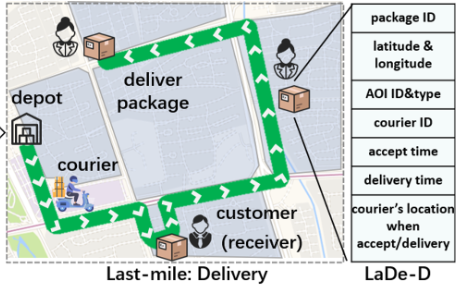 <br>

La imagen visualizada representa el modelo de distribución mediante el cual se recolectaron los datos. A continuación, procederemos a analizar el DataFrame para interpretar la información operativa que este representa.

Para lograr una comprensión profunda de nuestra logística y operación, el análisis se centrará en los siguientes pilares fundamentales:

### <font color="#1E88E5">Dimensiones de Análisis</font> <br>

El esquema de datos nos permite abordar el problema desde tres frentes principales:

* **Identificación de Patrones Geográficos:** Evaluaremos la densidad de los puntos de entrega y recepción para detectar zonas de alta demanda o posibles cuellos de botella operativos.

* **Traducción de Datos en Decisiones:** Buscamos transformar las métricas espaciales en información accionable que permita optimizar las rutas y mejorar los tiempos de respuesta.

Este enfoque analítico busca transformar datos crudos en estrategias accionables para optimizar los recursos logísticos, asegurando que cada dato contribuya directamente a la eficiencia de nuestra red operativa.

In [ ]:
# ANALISIS DE GEOLOCALIZACIONES
# Nos interesa saber cuantos puntos geográficos hay en el df.
conteo_accept_lng_lat = df.groupby(['accept_gps_lng', 'accept_gps_lat'])
total_accept_lng_lat = len(conteo_accept_lng_lat)
print(f"La cantidad de puntos accept_lng_lat es {total_accept_lng_lat}")

conteo_lng_lat = df.groupby(['lng', 'lat'])
total_lng_lat = len(conteo_lng_lat)
print(f"La cantidad de puntos lng_lat es {total_lng_lat}")

conteo_delivery_lng_lat = df.groupby(['delivery_gps_lng', 'delivery_gps_lat'])
total_delivery_lng_lat = len(conteo_delivery_lng_lat)
print(f"La cantidad de puntos accept_delivery_lng_lat es {total_delivery_lng_lat}")


La cantidad de puntos accept_lng_lat es 24519
La cantidad de puntos lng_lat es 1079082
La cantidad de puntos accept_delivery_lng_lat es 1160540


In [ ]:
#ANALISIS GEOLOCALIZACIONES CON 3 DIGITOS (PRECISIÓN 111 MTS)
# 1. Conteo de puntos de aceptación redondeados (Localización del paquete)
conteo_accept = df.groupby(
    [df["accept_gps_lng"].round(3), df["accept_gps_lat"].round(3)]
)
print(f"La cantidad de puntos accept_lng_lat (redondeado) es: {len(conteo_accept)}")

# 2. Conteo de puntos de donde estaba el courier en el momento de la aceptación.
conteo_origen = df.groupby([df["lng"].round(3), df["lat"].round(3)])
print(f"La cantidad de puntos lng_lat (redondeado) es: {len(conteo_origen)}")

# 3. Conteo de puntos de destino/entrega redondeados (A dónde llega el paquete)
conteo_delivery = df.groupby(
    [df["delivery_gps_lng"].round(3), df["delivery_gps_lat"].round(3)]
)
print(
    f"La cantidad de puntos delivery_lng_lat (redondeado) es: {len(conteo_delivery)}"
)

La cantidad de puntos accept_lng_lat (redondeado) es: 86
La cantidad de puntos lng_lat (redondeado) es: 40563
La cantidad de puntos delivery_lng_lat (redondeado) es: 52164


In [ ]:
# En funciòn del hallazgo anterior, redondeamos estás coordenadas para tener
#unicidad de puntos georeferenciables.
df['accept_gps_lng'] = df['accept_gps_lng'].round(3)
df['accept_gps_lat'] = df['accept_gps_lat'].round(3)
# bajamos de 24748 ubicaciones distintas de accept, a 88 ubicaciones distintas

In [ ]:
# 2. Agrupamos por el par de aceptación para generar el índice único del hub (1 al 86)
# .ngroup() le asigna el mismo número a las filas que tengan las mismas coordenadas redondeadas
df['hub_id'] = df.groupby(['accept_gps_lng', 'accept_gps_lat']).ngroup() + 1


# 4. Verificación de control para tu tranquilidad
print(f"Verificación: Se han generado exactamente {df['hub_id'].nunique()} hubs únicos.")

Verificación: Se han generado exactamente 86 hubs únicos.


In [ ]:
# ahora hacemos gráfica para saber cuales son los puntos de logística mas importantes
# crear un nuevo df con las coordenadas únicas de aceptación.
coordenadas_unicas = df.groupby(['accept_gps_lng', 'accept_gps_lat']).agg({'order_id': 'count'}).reset_index()
coordenadas_unicas.columns = ['accept_gps_lng', 'accept_gps_lat', 'count']

# Creamos un mapa
mapa = folium.Map(
    location=[coordenadas_unicas['accept_gps_lat'].mean(),
              coordenadas_unicas['accept_gps_lng'].mean()],
    zoom_start=11
)

# Agregar los puntos con radio proporcional al count
for i, row in coordenadas_unicas.iterrows():
    # Escalar el radio según el count (ajusta el divisor según tus datos)
    radio = max(3, row['count'] / 1000)  # Mínimo 3, luego proporcional a count

    folium.CircleMarker(
        location=[row['accept_gps_lat'], row['accept_gps_lng']],
        radius=radio,
        popup=f"Orders: {row['count']}",
        color='blue',
        fill=True,
        fill_color='blue',
        fill_opacity=0.7
    ).add_to(mapa)

mapa


In [ ]:
#  -------------------- CALCULO DE LA NUEVA VARIABLE TRANSIT_TIME
#  ----------------------- ajuste de formato de los timestamp ----------------
# ajustamos el formato a datetime para poder calcular la diferencia de tiempo
# Seteamos el año 2023 porque el campo viene sin año, e identificamos en la documentación que corresponden a datos del 2023
format_str = '%m-%d %H:%M:%S'
df['accept_time'] = pd.to_datetime(df['accept_time'], format=format_str)
df['accept_time'] = df['accept_time'].apply(lambda dt: dt.replace(year=2023))

df['delivery_time'] = pd.to_datetime(df['delivery_time'], format=format_str)
df['delivery_time'] = df['delivery_time'].apply(lambda dt: dt.replace(year=2023))

In [ ]:
# Exploratorio de fechas
min_delivery = df['delivery_time'].min()
max_delivery = df['delivery_time'].max()
print(f'Las fechas de entrega van desde {min_delivery} hasta {max_delivery}')

Las fechas de entrega van desde 2023-05-01 08:33:00 hasta 2023-11-16 23:09:00


In [ ]:
## -------------------------- TRANSIT_TIME

## Calculo de una nueva columa transit_time, que equivale a la diferencia de tiempo entre accept_time y delivery_time

# Calcular el  "transit time", en minutos y en horas
df['transit_time'] = (df['delivery_time'] - df['accept_time']).dt.total_seconds() / 60  # en minutos
df['transit_time_hours'] = df['transit_time'] / 60  # en horas

# **Análisis detallado de las métricas - KPIs**







"¿Cuáles son los factores geográficos y temporales que mayor impacto tienen en los tiempos de entrega de 'última milla' en Shanghái, y cómo puede utilizarse esta información para optimizar el rendimiento de la flota y garantizar mejores promesas de servicio?"

**1. KPI: Tiempo Promedio de Tránsito (Average Transit Time)**


**2. KPI: Tasa de Entregas a Tiempo / Cumplimiento (On-Time Delivery - OTD / SLA)**


**3. KPI: Productividad y Rendimiento del Driver**


**4. KPI: Eficiencia por Ventanas Horarias y Temporalidad**


**5. KPI: Rendimiento Geográfico (Zonas Críticas)**


# **1. KPI: Tiempo Promedio de Tránsito (Average Transit Time)**





Qué mide: El tiempo real que toma el trayecto de última milla. Se relaciona directamente con el objetivo de medir el "Tiempo promedio de tránsito" y "Segmentar en tiempos de entrega".

Calculando la diferencia exacta entre el momento de aceptación del servicio y el momento de entrega efectiva.

Fórmula = (accept_time) - (delivery_time)




In [ ]:
# --------------  ANALISIS de la nueva variable TRANSIT_TIME
# nos preguntamos si hay muchos registros con tiempos mayores a un dia. o cero
df.sort_values(by='transit_time', ascending=False)
#Hay muchos registros que sean mayores a 24hs ?
len(df[df['transit_time'] > 1440])

2345

In [ ]:
# hay registros de tiempos nulos o outliers?
df[['transit_time']].describe()
# vemos un mínimo de 0min y máximo de 47739min = 33.15 dias
# vamos a analizar cómo se distribuyen esos valores

,transit_time
count,1.188422e+06
mean,1.098553e+02
std,1.917881e+02
min,0.000000e+00
25%,4.300000e+01
50%,7.200000e+01
75%,1.190000e+02
max,4.773900e+04


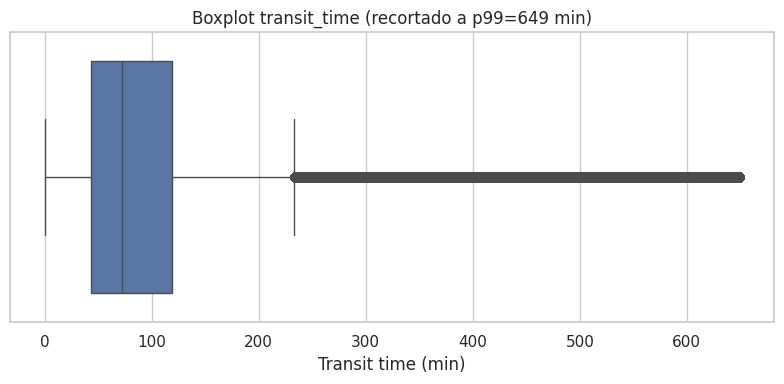

In [ ]:
# gráfico de caja de la variable TRANSIT_TIME
# es para ver cómo se distribuyen los valores, para quizá sacar valores extremos del análisis
# dados los resultados podriamos usar, para análisis de tiempos los registros que estén entre transit_time: 0.5 min ≤ transit_time ≤ 720 min (12 h)
x = df['transit_time'].dropna()
p99 = x.quantile(0.99)
x_clip = x.clip(upper=p99)

plt.figure(figsize=(8,4))
sns.boxplot(x=x_clip, color='C0', whis=1.5)   # whis ajusta longitud de bigotes
plt.xlabel('Transit time (min)')
plt.title(f'Boxplot transit_time (recortado a p99={p99:.0f} min)')
plt.xscale('linear')  # usa 'log' si la distribución está muy sesgada: plt.xscale('log')
plt.tight_layout()
plt.show()

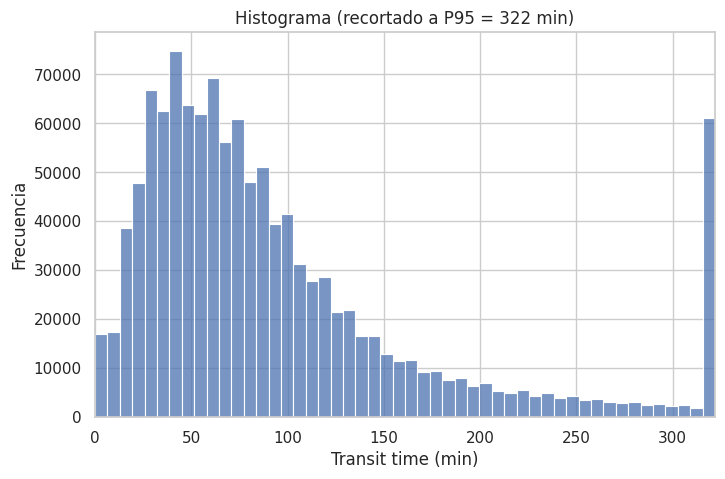

In [ ]:
# HISTOGRAMA de la variable TRANSIT_TIME
# cómo se distribuyen los valores de transit_time
# hacer gráfica para ver la distribución de valores

p95 = 322  # min
data = df['transit_time'].dropna().clip(upper=p95)

plt.figure(figsize=(8,5))
sns.histplot(data, bins=50, color='C0')
plt.xlim(0, p95)
plt.xlabel('Transit time (min)')
plt.ylabel('Frecuencia')
plt.title(f'Histograma (recortado a P95 = {p95} min)')
plt.show()


In [ ]:
# OPCIONAL me quedo con los registros que cumplen transit_time: 0.5 min ≤ transit_time ≤ 720 min (12h), o 300 min (5h)
# creo un nuevo dataframe df_filtered que se queda solo con los registros que quiero.
#df_ftt es el dataframe filtrado, sin los valores excepcionales de Transit Time.
df_ftt = df[(df['transit_time'] >= 0.5) & (df['transit_time'] <= 1440)].copy()
n_total = len(df)
n_filtered = len(df_ftt)
print(f"filas totales: {n_total}, filtradas: {n_filtered}, descartadas: {n_total-n_filtered}")

filas totales: 1188422, filtradas: 1183842, descartadas: 4580


In [ ]:
# si me sirve usar el dataset filtrado en vez del original, ejecuto esta linea
df = df_ftt.copy()

In [ ]:
# Calcular el "average transit time"
average_transit_time = df['transit_time'].mean()
median_transit_time = df['transit_time'].median()
min_transit_time= df['transit_time'].min()
max_transit_time= df['transit_time'].max()

print(f"Tiempo Promedio de Tránsito: {average_transit_time:.2f} minutos")
print(f"Tiempo Mínimo de Tránsito: {min_transit_time:.2f} minutos")
print(f"Tiempo Máximo de Tránsito: {max_transit_time:.2f} minutos")
print(f"Tiempo Mediano de Tránsito: {median_transit_time:.2f} minutos")

Tiempo Promedio de Tránsito: 104.90 minutos
Tiempo Mínimo de Tránsito: 1.00 minutos
Tiempo Máximo de Tránsito: 1440.00 minutos
Tiempo Mediano de Tránsito: 72.00 minutos


RESULTADO:


# **2. KPI: Tasa de Entregas a Tiempo / Cumplimiento (On-Time Delivery - OTD / SLA)**

Qué mide: La capacidad de la flota para cumplir con las promesas hechas al cliente.

"¿Qué porcentaje de entregas se realizan en menos de 24hs?" y qué tiempo prometer para "cumplir con un desvío menor al 2%".

Con el dato obtenido en el KPI previo, podemos obtener un análisis de los diferentes bloques de demora en la entrega por ejemplo, cuales demoran menos de 2 horas, cuales entre 2 horas y 4 horas, y cuales más de 4 horas hasta 24horas, y si ha exitido casos mayores a 24 horas
Debemos definir cual es el target para luego calcular el desvío, por ejemplo si el target es mejor a 4 horas, entonces todas las que sean mayores serán parte del desvío.


/tmp/ipykernel_2023/1557064666.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_franjas = df.groupby('franja_horaria', as_index=False).size() # el size() a diferencia del count(), ya me lo separa en 2, y luego le pongo nombres


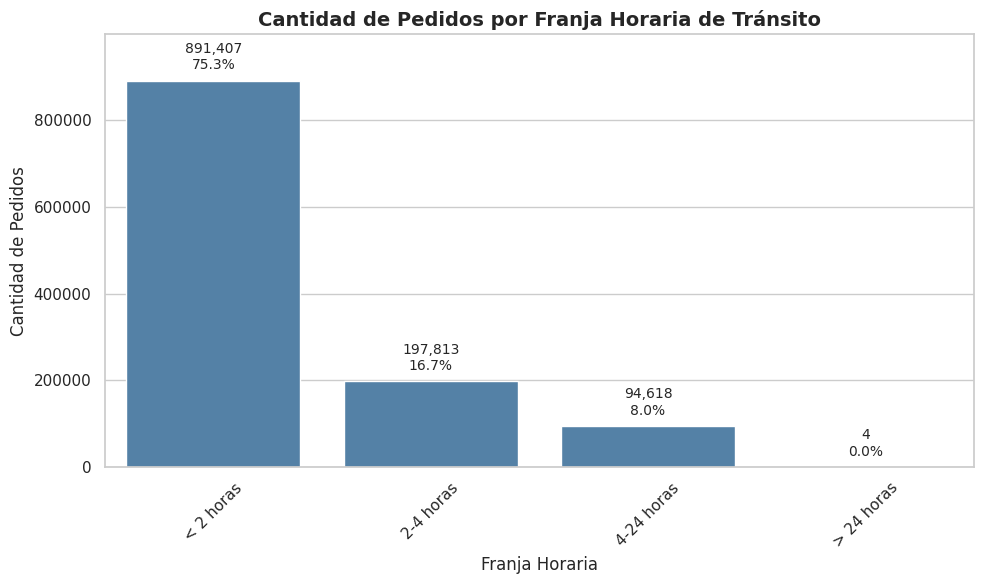

In [ ]:
# Queremos ver un panorama general de los tiempos de entrega
# para eso realizamos una gráfica que nos muestra la cantidad de pedidos entregados durante distintas franjas horarias

# Crear franjas horarias personalizadas
bins = [0, 120, 240, 1440, float('inf')]   # minutos: <2h, 2-4h, 4-24h, >24h
labels = ['< 2 horas', '2-4 horas', '4-24 horas', '> 24 horas']


# Asignar cada pedido a su franja horaria en una nueva columna
# pd.cut
#       bins	Lista de límites de intervalos o número de bins automáticos
#       lables Nombres personalizados para cada intervalo
df['franja_horaria'] = pd.cut(df['transit_time'], bins=bins, labels=labels, right=False)

# Agrupar por franja horaria y contar pedidos
df_franjas = df.groupby('franja_horaria', as_index=False).size() # el size() a diferencia del count(), ya me lo separa en 2, y luego le pongo nombres
df_franjas.columns = ['franja_horaria', 'cantidad_pedidos']

# Para los porcentajes
total = df_franjas['cantidad_pedidos'].sum()
df_franjas['pct'] = df_franjas['cantidad_pedidos'] / total * 100

# Gráfico
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_franjas, x='franja_horaria', y='cantidad_pedidos', color='steelblue')
plt.title('Cantidad de Pedidos por Franja Horaria de Tránsito', fontsize=14, fontweight='bold')
plt.xlabel('Franja Horaria', fontsize=12)
plt.ylabel('Cantidad de Pedidos', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

# ajustar ylim un poco por encima del máximo para que entren las etiquetas
ymax = df_franjas['cantidad_pedidos'].max()
ax.set_ylim(0, ymax * 1.12)   # 12% de espacio arriba

# etiquetas encima de cada barra
for p, pct in zip(ax.patches, df_franjas['pct']):
    height = int(p.get_height())
    ax.annotate(f'{height:,}\n{pct:.1f}%',             # cuenta + porcentaje
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 6),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10)


plt.show()


Introduce el porcentaje de pedidos meta (ej. 85): 98

--- RESULTADO DE LA EVALUACIÓN OPERATIVA ---
-> Para alcanzar el 98.0% de los pedidos totales acumulados,
   el tiempo de tránsito máximo estimado es de: 8.45 horas.


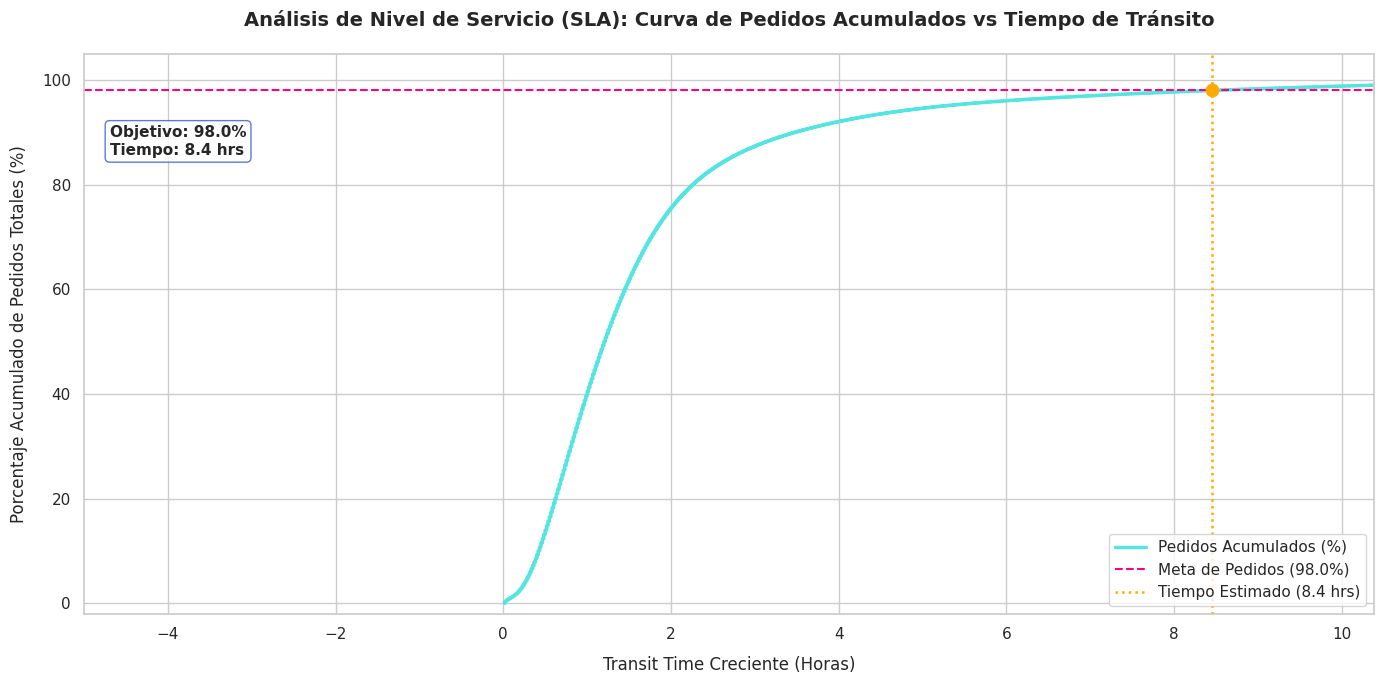

In [ ]:
# 1. PREPARACIÓN DE LA DISTRIBUCIÓN ACUMULADA (ECDF)
# Ordenamos los tiempos de tránsito de menor a mayor de forma creciente
transit_sorted = np.sort(df_ftt['transit_time_hours'])

# Calculamos el porcentaje acumulado para cada punto de datos
# np.arange(1, len+1) / len nos da una escala exacta de 0% a 100% (o 0 a 1)
porcentaje_acumulado = (np.arange(1, len(transit_sorted) + 1) / len(transit_sorted)) * 100

# 2. CAPTURA DEL INPUT INTERACTIVO Y CÁLCULO DE ESTIMACIÓN (Cruce)
# Solicitamos el porcentaje meta al usuario (ej: 80 o 90)
input_usuario = input("Introduce el porcentaje de pedidos meta (ej. 85): ")
pct_objetivo = float(input_usuario)

# Validamos que el input esté dentro de un rango lógico
if not (0 <= pct_objetivo <= 100):
    raise ValueError("El porcentaje debe ser un valor entre 0 y 100.")

# INTERPOLACIÓN MATEMÁTICA: Encuentra el valor exacto de transit_time (X)
# donde el porcentaje acumulado alcanza el pct_objetivo (Y)
tiempo_estimado = np.interp(pct_objetivo, porcentaje_acumulado, transit_sorted)

print(f"\n--- RESULTADO DE LA EVALUACIÓN OPERATIVA ---")
print(f"-> Para alcanzar el {pct_objetivo}% de los pedidos totales acumulados,")
print(f"   el tiempo de tránsito máximo estimado es de: {tiempo_estimado:.2f} horas.")

# =====================================================================
# 3. RENDERIZADO DEL GRÁFICO DE ALTA CALIDAD
# =====================================================================
plt.rcParams['figure.figsize'] = (14, 7)
sns.set_theme(style="whitegrid")

# Dibujamos la línea de distribución acumulada (Estilo Neon Shanghai Cyan)
plt.plot(transit_sorted, porcentaje_acumulado, color='#54e5e0', linewidth=2.5, label='Pedidos Acumulados (%)')

# Dibujamos la línea horizontal punteada del objetivo (Estilo Neon Magenta)
plt.axhline(y=pct_objetivo, color='#ff007f', linestyle='--', linewidth=1.5,
            label=f'Meta de Pedidos ({pct_objetivo}%)')

# Dibujamos la línea vertical punteada que baja al eje X en el tiempo estimado
plt.axvline(x=tiempo_estimado, color='#ffaa00', linestyle=':', linewidth=1.8,
            label=f'Tiempo Estimado ({tiempo_estimado:.1f} hrs)')

# Marcamos el punto exacto de intersección en el gráfico
plt.scatter(tiempo_estimado, pct_objetivo, color='#ffaa00', s=80, zorder=5)

# 4. ESTÉTICA Y DETALLES DEL LIENZO
plt.title('Análisis de Nivel de Servicio (SLA): Curva de Pedidos Acumulados vs Tiempo de Tránsito', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Transit Time Creciente (Horas)', fontsize=12, labelpad=10)
plt.ylabel('Porcentaje Acumulado de Pedidos Totales (%)', fontsize=12, labelpad=10)

# Limitamos el eje Y estrictamente de 0 a 105% para que luzca perfecto
plt.ylim(-2, 105)

# Para mejorar la visualización si tienes outliers extremos en el eje X,
# limitamos la vista al Percentil 99 de los datos para que el gráfico no se comprima a la izquierda
plt.xlim(-5, np.percentile(transit_sorted, 99))

# Añadimos un cuadro de texto con la conclusión en el gráfico
texto_resumen = f"Objetivo: {pct_objetivo}%\nTiempo: {tiempo_estimado:.1f} hrs"
plt.gca().text(0.02, 0.82, texto_resumen, transform=plt.gca().transAxes, fontsize=11,
            fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='#365ac3'))

plt.legend(loc='lower right', fontsize=11, frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
#Para garantizar el 98% de cumplimiento, la promesa de servicio optima es de [X] horas según el percentil P98
# Percentil 98 de la variable transit_time
p98 = df_ftt['transit_time_hours'].quantile(0.98)
print(f"Percentil 98 de la variable transit_time: {p98:.2f} horas")
# Un percentil 98 de 525min sin limpiar datos
# Un percentil 98 de 252min usando el dataset_filetered_2

Percentil 98 de la variable transit_time: 8.45 horas


In [ ]:
# Respondemos la pregunta del KPI 2.
# "¿Qué porcentaje de entregas se realizan en menos de 24hs?" y qué tiempo prometer para "cumplir con un desvío menor al 2%".
# Calculo de cumplimiento target: pedidmos > a 24Hs. menor al 2%

total_pedidos = len(df)
pedidos_mayor_24_horas = len(df[df['transit_time'] > 1440])
pedidos_menores_2_horas = len(df[df['transit_time'] < 120])

porcentaje_mayor_24_horas = (pedidos_mayor_24_horas / total_pedidos) * 100
porcentaje_menores_2_horas = (pedidos_menores_2_horas / total_pedidos) * 100

print(f"Cantidad de pedidos mayor a 24 horas de tránsito: {pedidos_mayor_24_horas}")
print(f"Porcentaje de pedidos mayor a 24 horas de tránsito: {porcentaje_mayor_24_horas:.2f}%")

print(f"Cantidad de pedidos menores a 2 horas de tránsito: {pedidos_menores_2_horas}")
print(f"Porcentaje de pedidos menores a 2 horas de tránsito: {porcentaje_menores_2_horas:.2f}%")

# hay 0% porcentaje de pedidos mayor a 24hs porque recortamos el dataset a pedidos menores de 12 hs.

Cantidad de pedidos mayor a 24 horas de tránsito: 0
Porcentaje de pedidos mayor a 24 horas de tránsito: 0.00%
Cantidad de pedidos menores a 2 horas de tránsito: 891407
Porcentaje de pedidos menores a 2 horas de tránsito: 75.30%


RESULTADO:

#**3. KPI: Productividad y Rendimiento del Driver**

Qué mide: La eficiencia individual o comparativa de los repartidores para detectar quiénes optimizan mejor sus tiempos.

"¿Qué couriers/deliverys tienen mayor/menor tiempo promedio entre aceptación y entrega?".

Utilizaremos la variable courier_id, analizando el desempeño de los 1.733 perfiles distintos.

In [ ]:
# para calcular nuestra variable de eficiencia que será la distancia/tiempo (distancia entre los puntos de aceptacion y entrega / tiempo entre los puntos)
# con geopandas obtenemos la distancia euclideana entre 2 puntos: La ubicacion de aceptacion y la ubicación de entrega.
#
# _____ ESTA EJECUCIÓN TOMA 1 min _______________
# Convertir coordenadas a geometría
df['punto_inicial'] = [Point(xy) for xy in zip(df['accept_gps_lng'], df['accept_gps_lat'])]
df['punto_final'] = [Point(xy) for xy in zip(df['delivery_gps_lng'], df['delivery_gps_lat'])]

# Usamos el parametro crs, porque fue una sugerencia de llm para un mejor y mas exacto calculo de la distancia para Shangai
gdf_init = gpd.GeoDataFrame(df, geometry='punto_inicial', crs='EPSG:4326')

# GeoSeries para puntos finales con mismo CRS
finals = gpd.GeoSeries(df['punto_final'], crs='EPSG:4326')

# Reproyectar ambos a EPSG:32651 (UTM zone 51N)
gdf_32651 = gdf_init.to_crs('EPSG:32651')
finals_32651 = finals.to_crs('EPSG:32651')

# Calcular distancia en metros (geom de gdf_32651 vs finals_32651)
gdf_32651['distance_m'] = gdf_32651.geometry.distance(finals_32651)

# Pasar la columna de vuelta al DataFrame original
df['distance_m'] = gdf_32651['distance_m'].values

print(df[['accept_gps_lng', 'accept_gps_lat', 'delivery_gps_lng', 'delivery_gps_lat', 'distance_m']].head())


    accept_gps_lng  accept_gps_lat  delivery_gps_lng  delivery_gps_lat  \
10         121.523          31.106         121.52200          31.06521   
12         121.523          31.108         121.52112          31.06712   
13         121.523          31.106         121.52121          31.06622   
14         121.523          31.106         121.52116          31.06736   
15         121.523          31.106         121.52120          31.06620   

     distance_m  
10  4522.730874  
12  4535.251238  
13  4413.068566  
14  4286.985745  
15  4415.320986  


In [ ]:
# ANALISIS DE LA NUEVA COLUMNA DISTANCE_M
print(df['distance_m'].describe())
# Vamos a ver que tantos valores en 0 hay para las variables distance_m y transit_time
df.loc[df['distance_m']==0]
# 2 registros con distance_m = 0

count    1.183842e+06
mean     3.662212e+03
std      1.757200e+05
min      9.524237e-01
25%      1.057068e+03
50%      1.722897e+03
75%      2.614434e+03
max      2.467100e+07
Name: distance_m, dtype: float64


,order_id,region_id,city,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_lng,...,delivery_gps_lat,ds,grupo_pedidos,hub_id,transit_time,transit_time_hours,franja_horaria,punto_inicial,punto_final,distance_m


In [ ]:
# eliminamos filas con valores de distacia = 0
df = df[df['distance_m'] != 0]

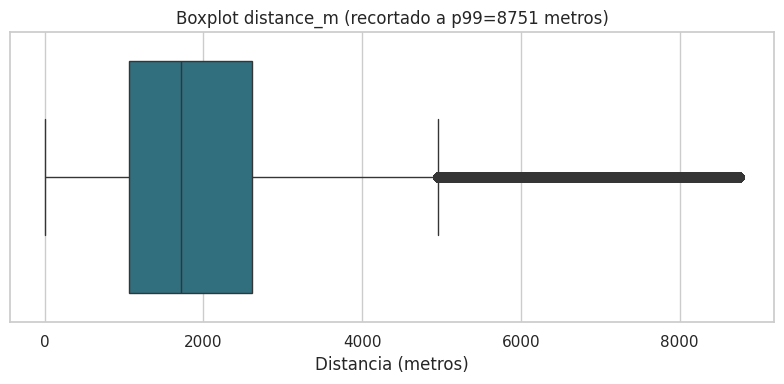

In [ ]:
# Veamos cómo se distribuyen las distancias
x = df['distance_m'].dropna()
p99 = x.quantile(0.99)
x_clip = x.clip(upper=p99)


plt.figure(figsize=(8,4))

#-----paleta
cmap = sns.color_palette("crest", as_cmap=True)
color = cmap(0.6)
#-----paleta

sns.boxplot(x=x_clip, color=color, whis=1.5)
plt.xlabel('Distancia (metros)')
plt.title(f'Boxplot distance_m (recortado a p99={p99:.0f} metros)')
plt.xscale('linear')
plt.tight_layout()
plt.show()

In [ ]:
# KPIs para medir rendimiento:
# Unas de las formas posibles de medir rendimiento es
# ratio km/h
# m/seg * 3,6 = k/h
# df['ratio_kmh'] = (df['distance_m'] / df['transit_time']) * 3.6
df['ratio_kmh'] = (df['distance_m']/1000) / (df['transit_time']/60)

# Minutos por kilómetro (más práctico)
# df['ratio_minkm'] = (df['transit_time'] * 1000) / (df['distance_m'] * 60)
df['ratio_minkm'] = df['transit_time'] / (df['distance_m']/1000)

# Ver ejemplos
print(df[['distance_m', 'transit_time', 'ratio_kmh','ratio_minkm']].head())

# Estadísticas de estas 2 nuevas columnas
print(df[['ratio_kmh','ratio_minkm']].describe())
print(df.shape)

# evaluar cual indicador es mas mejor.
# ver cómo poder listar los couriers con mejor tiempo. y graficar de alguna manera.
# ver como marcar en el mapa los curiers con peor tiempo, o las locaciones con peor tiempo...
# hacer una categorizacion dicho KPI, el que sea

     distance_m  transit_time  ratio_kmh  ratio_minkm
10  4522.730874          40.0   6.784096     8.844214
12  4535.251238         357.0   0.762227    78.716698
13  4413.068566         507.0   0.522257   114.886046
14  4286.985745         237.0   1.085313    55.283599
15  4415.320986         569.0   0.465587   128.869453
          ratio_kmh   ratio_minkm
count  1.183842e+06  1.183842e+06
mean   4.124638e+00  1.276624e+02
std    3.835921e+02  1.051716e+03
min    1.190530e-04  1.646292e-04
25%    7.694277e-01  2.404300e+01
50%    1.406530e+00  4.265817e+01
75%    2.495529e+00  7.798003e+01
max    3.644553e+05  5.039774e+05
(1183842, 25)


In [ ]:
# ver cómo poder listar los couriers con mejor tiempo. y graficar de alguna manera.
# ahora que tenemos las velocidades y minutos_por_km limpios. Agrupamos top y botom para graficar.


#Agrupar por courier, la mediana de velocidad_kmh, minutos_por_km y transit_time
df_courier = df.groupby('courier_id', as_index=False).agg({
    'ratio_kmh': 'median',
    'ratio_minkm': 'median',
    'transit_time': 'median'
})
df_courier

,courier_id,ratio_kmh,ratio_minkm,transit_time
0,1,1.140533,52.607004,74.0
1,12,1.538005,39.011575,66.0
2,40,1.115800,53.773080,51.0
3,46,1.107324,54.184704,85.0
4,74,2.371019,25.305576,55.0
...,...,...,...,...
358,4826,1.681135,35.690165,62.0
359,4832,1.210620,49.561387,54.0
360,4834,2.574529,23.305236,167.0
361,4869,0.432807,138.629947,85.0


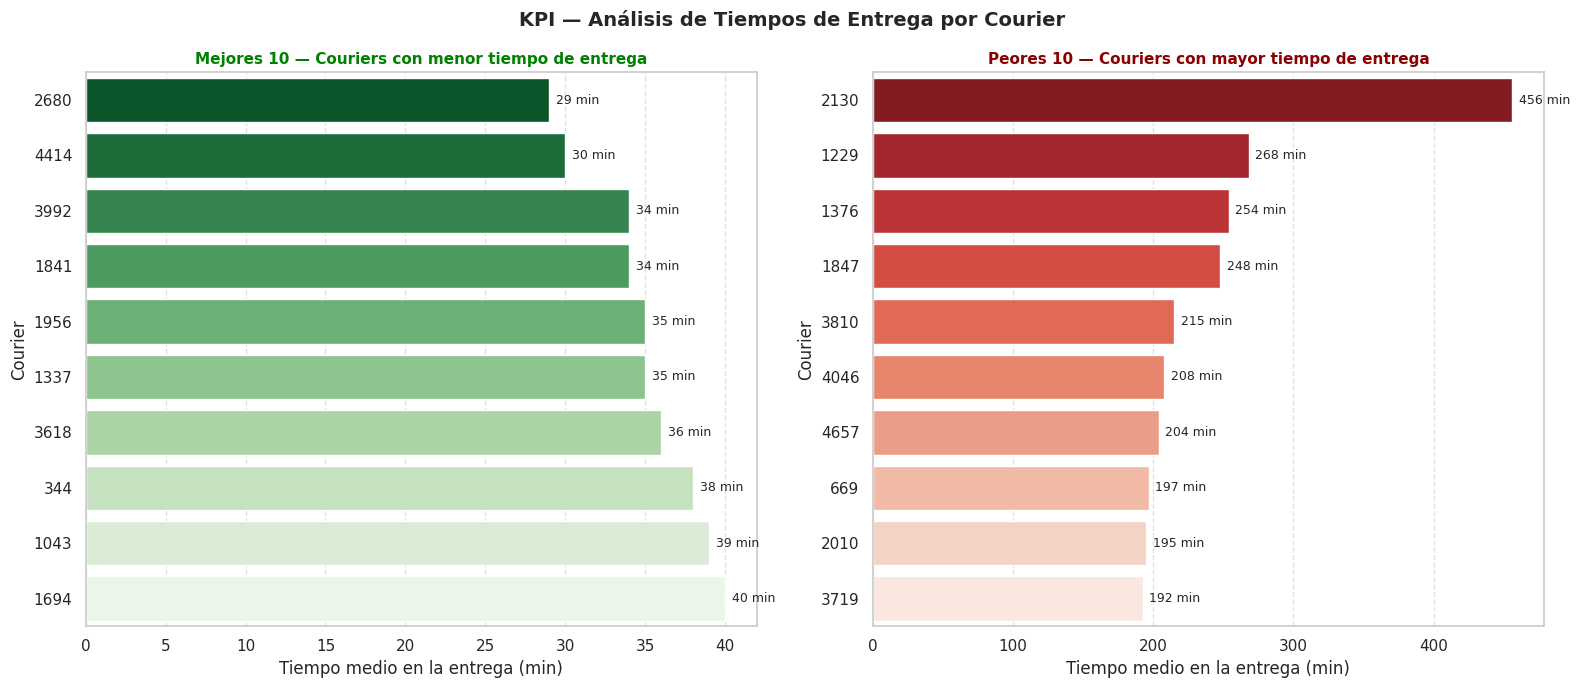

In [ ]:
# GRAFICA TOP 10 TRANSIT_TIME POR COURIER

# graficar top 10 courier y sus transit_time (los que demoran menos por km)

# 1. Preparar datos (Top 10 mejores y peores)
top_n = 10
df_sorted = df_courier.sort_values(by='transit_time', ascending=False)

# Peores: Mayor transit_time (ordenados de mayor a menor para el gráfico horizontal)
df_peores = df_sorted.head(top_n).copy()
df_peores['courier_id'] = df_peores['courier_id'].astype(str)

# Mejores: Menor transit_time (ordenados de menor a mayor para el gráfico horizontal)
df_mejores = df_sorted.tail(top_n).sort_values(by='transit_time', ascending=True).copy()
df_mejores['courier_id'] = df_mejores['courier_id'].astype(str)


# 2. Armado de gráfico con 2 paneles estilizados
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharey=False)
fig.suptitle('KPI — Análisis de Tiempos de Entrega por Courier', fontsize=14, fontweight='bold')


# a. GRÁFICO IZQUIERDO: Mejores 10 (Menor transit_time)
sns.barplot(
    data=df_mejores,
    x='transit_time',
    y='courier_id',
    hue='courier_id',
    legend=False,
    orient='h',
    palette='Greens_r',  # Invertido para que el menor tiempo sea más oscuro/destacado
    ax=ax1,
    order=df_mejores['courier_id']
)
ax1.set_title(f'Mejores {top_n} — Couriers con menor tiempo de entrega',
              fontsize=11, fontweight='bold', color='green')
ax1.set_xlabel('Tiempo medio en la entrega (min)')
ax1.set_ylabel('Courier')
ax1.grid(axis='x', linestyle='--', alpha=0.6)

# Etiquetas de datos al final de cada barra horizontal
for patch, val in zip(ax1.patches, df_mejores['transit_time']):
    ax1.text(val + max(df_mejores['transit_time']) * 0.01, # Pequeño margen dinámico a la derecha
             patch.get_y() + patch.get_height() / 2,
             f'{val:.0f} min', va='center', fontsize=9)


# b. GRÁFICO DERECHO: Peores 10 (Mayor transit_time)
sns.barplot(
    data=df_peores,
    x='transit_time',
    y='courier_id',
    hue='courier_id',
    legend=False,
    orient='h',
    palette='Reds_r',  # Paleta roja para denotar bajo desempeño
    ax=ax2,
    order=df_peores['courier_id']
)
ax2.set_title(f'Peores {top_n} — Couriers con mayor tiempo de entrega',
              fontsize=11, fontweight='bold', color='darkred')
ax2.set_xlabel('Tiempo medio en la entrega (min)')
ax2.set_ylabel('Courier')
ax2.grid(axis='x', linestyle='--', alpha=0.6)

# Etiquetas de datos al final de cada barra horizontal
for patch, val in zip(ax2.patches, df_peores['transit_time']):
    ax2.text(val + max(df_peores['transit_time']) * 0.01,
             patch.get_y() + patch.get_height() / 2,
             f'{val:.0f} min', va='center', fontsize=9)


plt.tight_layout()
plt.show()

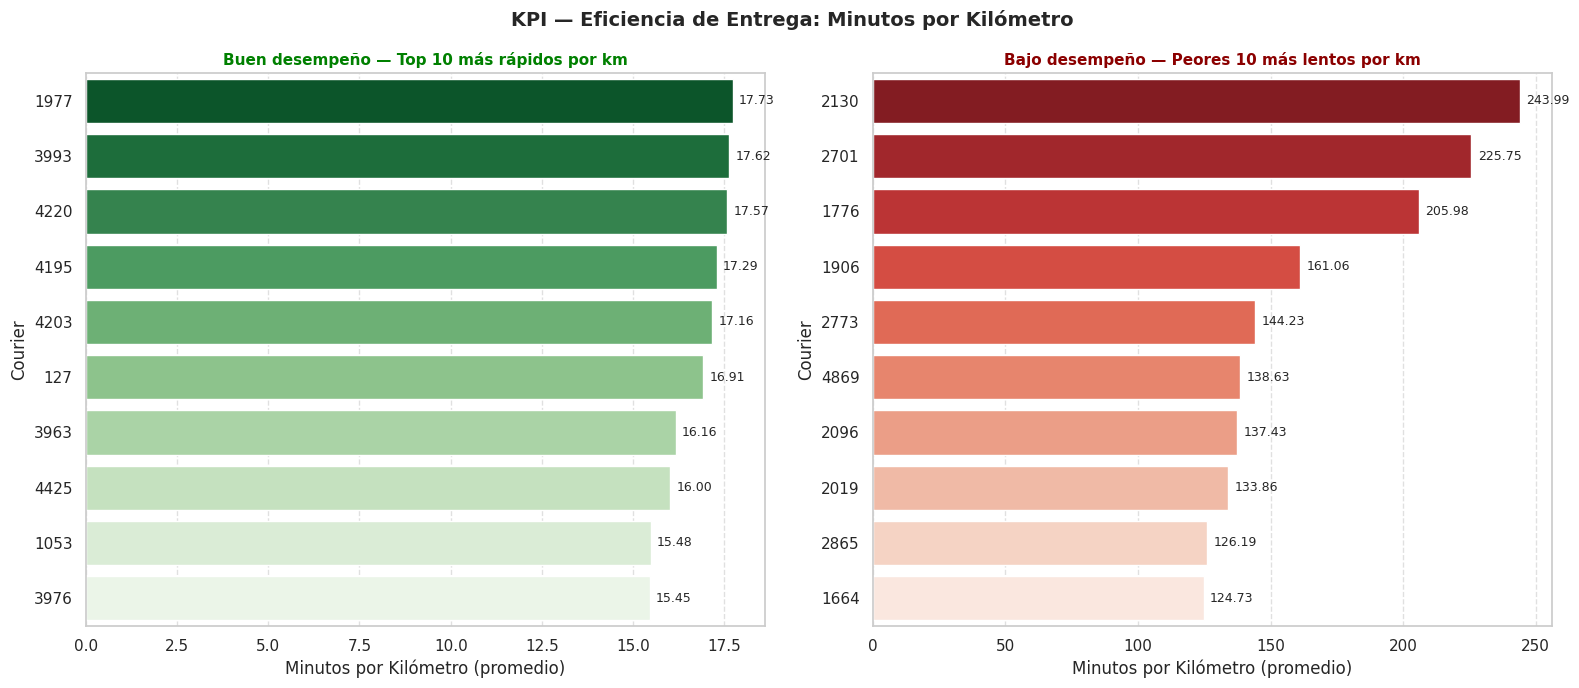

In [ ]:
# GRAFICA TOP 10 MINUTOS_POR_KM POR COURIER

# 1. Preparar datos (Mejores y Peores en minutos_por_km)
top_n = 10
# Ordenamos de menor a mayor (los que demoran menos por km son los mejores)
df_sorted = df_courier.sort_values(by='ratio_minkm', ascending=True)

# Mejores: Menor minutos_por_km (los primeros 10)
# Se invierte el orden para que en el gráfico horizontal el mejor quede arriba del todo
df_mejores = df_sorted.head(top_n).iloc[::-1].copy()
df_mejores['courier_id'] = df_mejores['courier_id'].astype(str)

# Peores: Mayor ratio_minkm (los últimos 10)
# Ordenados de mayor a menor para que el peor quede arriba del todo
df_peores = df_sorted.tail(top_n).sort_values(by='ratio_minkm', ascending=False).copy()
df_peores['courier_id'] = df_peores['courier_id'].astype(str)


# 2. Armado de gráfico con 2 paneles con el nuevo diseño
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharey=False)
fig.suptitle('KPI — Eficiencia de Entrega: Minutos por Kilómetro', fontsize=14, fontweight='bold')


# a. GRÁFICO IZQUIERDO: Mejores 10 (Menor minutos_por_km)
sns.barplot(
    data=df_mejores,
    x='ratio_minkm',
    y='courier_id',
    hue='courier_id',
    legend=False,
    orient='h',
    palette='Greens_r',  # Tonos verdes para el buen desempeño
    ax=ax1,
    order=df_mejores['courier_id']
)
ax1.set_title(f'Buen desempeño — Top {top_n} más rápidos por km',
              fontsize=11, fontweight='bold', color='green')
ax1.set_xlabel('Minutos por Kilómetro (promedio)')
ax1.set_ylabel('Courier')
ax1.grid(axis='x', linestyle='--', alpha=0.6)

# Etiquetas de datos al final de cada barra (con 2 decimales)
for patch, val in zip(ax1.patches, df_mejores['ratio_minkm']):
    ax1.text(val + max(df_mejores['ratio_minkm']) * 0.01, # Margen dinámico a la derecha
             patch.get_y() + patch.get_height() / 2,
             f'{val:.2f}', va='center', fontsize=9)


# b. GRÁFICO DERECHO: Peores 10 (Mayor ratio_minkm)
sns.barplot(
    data=df_peores,
    x='ratio_minkm',
    y='courier_id',
    hue='courier_id',
    legend=False,
    orient='h',
    palette='Reds_r',  # Tonos rojos para el bajo desempeño
    ax=ax2,
    order=df_peores['courier_id']
)
ax2.set_title(f'Bajo desempeño — Peores {top_n} más lentos por km',
              fontsize=11, fontweight='bold', color='darkred')
ax2.set_xlabel('Minutos por Kilómetro (promedio)')
ax2.set_ylabel('Courier')
ax2.grid(axis='x', linestyle='--', alpha=0.6)

# Etiquetas de datos al final de cada barra (con 2 decimales)
for patch, val in zip(ax2.patches, df_peores['ratio_minkm']):
    ax2.text(val + max(df_peores['ratio_minkm']) * 0.01,
             patch.get_y() + patch.get_height() / 2,
             f'{val:.2f}', va='center', fontsize=9)


plt.tight_layout()
plt.show()

In [ ]:
#Verificamos se el courier ganador es representativo.
#el courier ganador 1977, cuántos paquetes ha entregado
# contar cantidad de registros que tiene el courier_id=1977
courier= 1977
cantidad_de_ordenes = df[df['courier_id']==courier].shape[0]
print(f'El courier {courier} tiene {cantidad_de_ordenes} ordenes entregadas.')

El courier 1977 tiene 3076 ordenes entregadas.


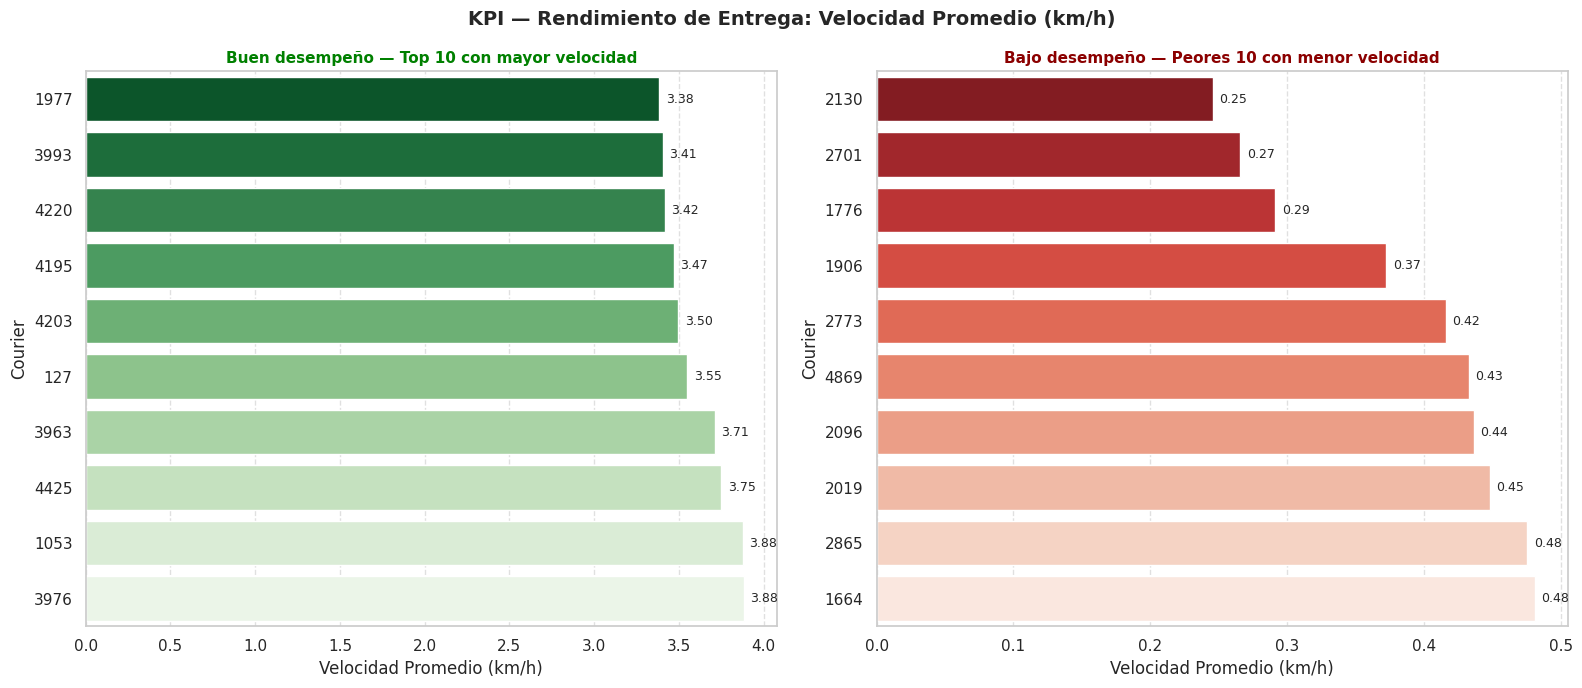

In [ ]:
# GRAFICA TOP 10 VELOCIDAD_KMH POR COURIER

# 1. Preparar datos (Mejores y Peores en velocidad_kmh)
top_n = 10
# Ordenamos de mayor a menor (los que van más rápido son los mejores)
df_sorted = df_courier.sort_values(by='ratio_kmh', ascending=False)

# Mejores: Mayor velocidad_kmh (los primeros 10)
# Se invierte el orden para que en el gráfico horizontal el más rápido quede arriba del todo
df_mejores = df_sorted.head(top_n).iloc[::-1].copy()
df_mejores['courier_id'] = df_mejores['courier_id'].astype(str)

# Peores: Menor velocidad_kmh (los últimos 10)
# Ordenados de menor a mayor para que el más lento quede arriba del todo en su panel
df_peores = df_sorted.tail(top_n).sort_values(by='ratio_kmh', ascending=True).copy()
df_peores['courier_id'] = df_peores['courier_id'].astype(str)


# 2. Armado de gráfico con 2 paneles estilizados
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharey=False)
fig.suptitle('KPI — Rendimiento de Entrega: Velocidad Promedio (km/h)', fontsize=14, fontweight='bold')


# a. GRÁFICO IZQUIERDO: Mejores 10 (Mayor velocidad_kmh)
sns.barplot(
    data=df_mejores,
    x='ratio_kmh',
    y='courier_id',
    hue='courier_id',
    legend=False,
    orient='h',
    palette='Greens_r',  # Tonos verdes para los más veloces
    ax=ax1,
    order=df_mejores['courier_id']
)
ax1.set_title(f'Buen desempeño — Top {top_n} con mayor velocidad',
              fontsize=11, fontweight='bold', color='green')
ax1.set_xlabel('Velocidad Promedio (km/h)')
ax1.set_ylabel('Courier')
ax1.grid(axis='x', linestyle='--', alpha=0.6)

# Etiquetas de datos al final de cada barra (con 2 decimales)
for patch, val in zip(ax1.patches, df_mejores['ratio_kmh']):
    ax1.text(val + max(df_mejores['ratio_kmh']) * 0.01, # Margen dinámico a la derecha
             patch.get_y() + patch.get_height() / 2,
             f'{val:.2f}', va='center', fontsize=9)


# b. GRÁFICO DERECHO: Peores 10 (Menor velocidad_kmh)
sns.barplot(
    data=df_peores,
    x='ratio_kmh',
    y='courier_id',
    hue='courier_id',
    legend=False,
    orient='h',
    palette='Reds_r',  # Tonos rojos para los más lentos
    ax=ax2,
    order=df_peores['courier_id']
)
ax2.set_title(f'Bajo desempeño — Peores {top_n} con menor velocidad',
              fontsize=11, fontweight='bold', color='darkred')
ax2.set_xlabel('Velocidad Promedio (km/h)')
ax2.set_ylabel('Courier')
ax2.grid(axis='x', linestyle='--', alpha=0.6)

# Etiquetas de datos al final de cada barra (con 2 decimales)
for patch, val in zip(ax2.patches, df_peores['ratio_kmh']):
    ax2.text(val + max(df_peores['ratio_kmh']) * 0.01,
             patch.get_y() + patch.get_height() / 2,
             f'{val:.2f}', va='center', fontsize=9)


plt.tight_layout()
plt.show()

In [ ]:
# PROMEDIOS de TRANSIT_TIME , o minutos_por_km

# Dado el transit_time

kpi_col = 'transit_time'   # o 'minutos_por_km'

# Agrupar por courier y calcular mean, std, count, CV
grp = (df.dropna(subset=[kpi_col, 'courier_id'])
       .groupby('courier_id')[kpi_col]
       .agg(['mean','std','count'])
       .rename(columns={'mean':'mean_min','std':'std_min','count':'n'}))

grp['cv'] = grp['std_min'] / grp['mean_min']  # coeficiente de variación (sin %)


# Ordenar por mean ascendente (más rápidos = menor tiempo por entrega)
grp_sorted = grp.sort_values('mean_min')

# Mostrar top N y construir la frase
top_n = 5
top = grp_sorted.head(top_n).reset_index()

# Top 1000 más rápidos
k = 100
top_k = grp_sorted.head(k).reset_index()
mean_top_k = top_k['mean_min'].mean() if len(top_k)>0 else float('nan')

# Top 100 más lentos
bottom_k = grp_sorted.tail(k).reset_index()           # los k más lentos
mean_bottom_k = bottom_k['mean_min'].mean() if len(bottom_k)>0 else float('nan')

# Imprimir top N y resumen del top k
for i, row in top.iterrows():
    courier = row['courier_id']
    mean_min = row['mean_min']
    cv = row['cv']
    print(f"Courier {courier} promedia {mean_min:.1f} min/entrega. CV = {cv:.2f} — inconsistencia {'alta' if cv>0.5 else 'moderada' if cv>0.2 else 'baja'}.")

best = top.iloc[0]
print("\nResumen:")
print(f"El courier más rápido (id={best['courier_id']}) promedia {best['mean_min']:.1f} min. CV = {best['cv']:.2f} — {'alta' if best['cv']>0.5 else 'moderada' if best['cv']>0.2 else 'baja'} inconsistencia.")
print(f"Promedio de los {min(k, len(grp_sorted))} couriers más rápidos: {mean_top_k:.1f} min.")
print(f"Promedio de los {min(k, len(grp_sorted))} couriers más lentos: {mean_bottom_k:.1f} min.")

Courier 2680.0 promedia 33.3 min/entrega. CV = 0.72 — inconsistencia alta.
Courier 4414.0 promedia 34.8 min/entrega. CV = 0.78 — inconsistencia alta.
Courier 3618.0 promedia 42.5 min/entrega. CV = 0.74 — inconsistencia alta.
Courier 1956.0 promedia 43.4 min/entrega. CV = 0.86 — inconsistencia alta.
Courier 3992.0 promedia 45.1 min/entrega. CV = 1.25 — inconsistencia alta.

Resumen:
El courier más rápido (id=2680.0) promedia 33.3 min. CV = 0.72 — alta inconsistencia.
Promedio de los 100 couriers más rápidos: 61.8 min.
Promedio de los 100 couriers más lentos: 174.1 min.


RESULTADO:

#**4. KPI: Eficiencia por Ventanas Horarias y Temporalidad**

Qué mide: Cómo fluctúa el rendimiento de la operación dependiendo del momento del día o la semana en que se trabaja.

"¿Cuántos paquetes se entregan según ventana horaria?", "¿Cómo varía la eficiencia de entrega según la hora del día?" y el análisis del "efecto del fin de semana". Cruzaremos los tiempos de entrega con el día de recolección (ds) y los horarios de aceptación.




In [ ]:
# Definimos la lista con las columnas a conservar para este indicador
columnas_copiar = [
    'region_id',
    'courier_id',
    'accept_gps_lng',
    'accept_gps_lat',
    'aoi_id',
    'aoi_type',
    'accept_time',
    'delivery_time',
    'ds',
    'grupo_pedidos',
    'hub_id',
    'transit_time_hours',
    'order_id'
]

df4 = df[columnas_copiar].copy()

# Verificamos
df4.head(1)

,region_id,courier_id,accept_gps_lng,accept_gps_lat,aoi_id,aoi_type,accept_time,delivery_time,ds,grupo_pedidos,hub_id,transit_time_hours,order_id
10,1,2621,121.523,31.106,450,1,2023-08-14 17:56:00,2023-08-14 18:36:00,814,Grupo 5 (Más pedidos),64,0.666667,3799613


In [ ]:
# 1. Agregamos la columna 'accept_hour' (extrae la hora como número de 0 a 23)
df4['accept_hour'] = df4['accept_time'].dt.hour

# 2. Agregamos la columna 'accept_weekday' (extrae el nombre del día en texto)
# en ingles generamos un diccionario para tener etiquetas en español
df4['accept_weekday'] = df4['accept_time'].dt.day_name()
traduccion_dias = {
    'Monday': 'Lunes', 'Tuesday': 'Martes', 'Wednesday': 'Miércoles',
    'Thursday': 'Jueves', 'Friday': 'Viernes', 'Saturday': 'Sábado', 'Sunday': 'Domingo'
}
df4['accept_weekday'] = df4['accept_weekday'].map(traduccion_dias)
#El método .map() actúa como un operador de transformación fila por fila.
# Cuando le pasas un diccionario como argumento,
# realiza un proceso de traducción automática basado en reglas estrictas:

# 3. Verificamos.
df4[['accept_time', 'accept_hour', 'accept_weekday']].head(1)

,accept_time,accept_hour,accept_weekday
10,2023-08-14 17:56:00,17,Lunes


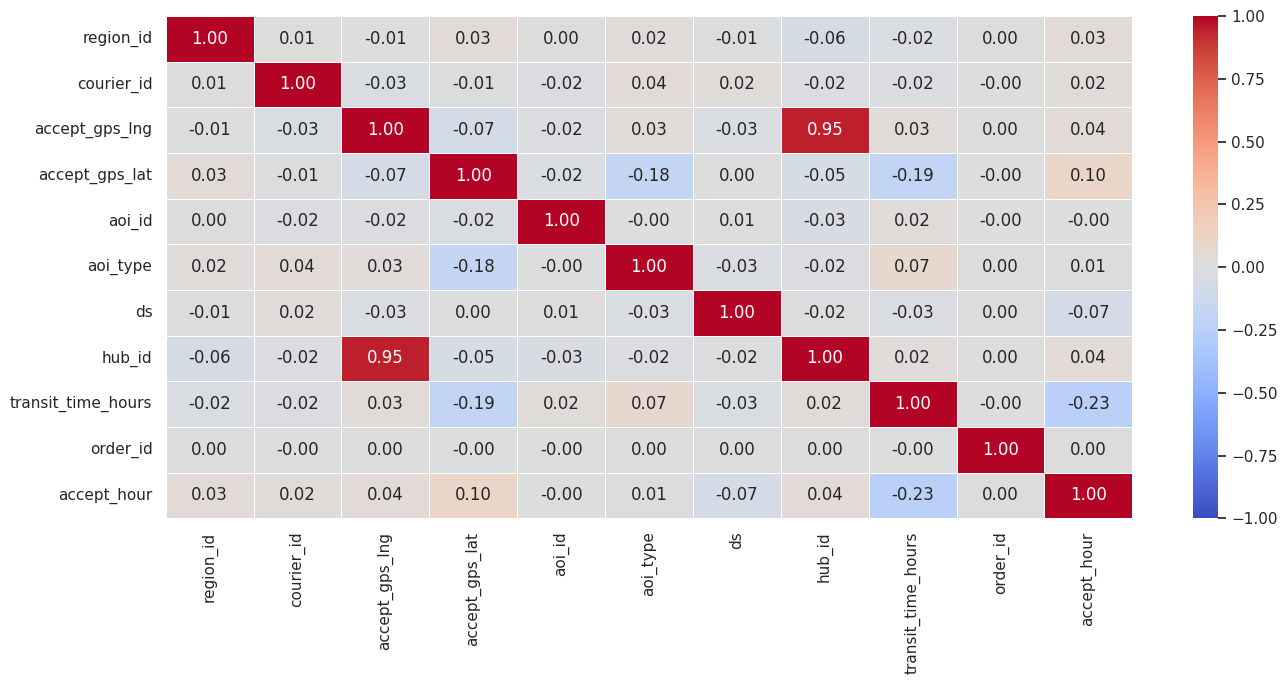

In [ ]:
# 1. Seleccionamos automáticamente solo las columnas que son números
df_numerico = df4.select_dtypes(include=["number"])

# 2. Calculamos la matriz de correlación (por defecto usa el método de Pearson)
matriz_correlacion = df_numerico.corr()

# 3. Dibujamos el Mapa de Calor (Heatmap)
# Nota: No usamos plt.figure() para evitar conflictos de tamaño, Seaborn lo ajustará
sns.heatmap(
    matriz_correlacion,
    annot=True,  # Muestra el número exacto de correlación en cada cuadro
    cmap="coolwarm",  # Escala de colores (Rojo = Positivo, Azul = Negativo)
    fmt=".2f",  # Muestra solo 2 decimales
    linewidths=0.5,  # Separa los cuadros con una línea delgada
    vmin=-1,
    vmax=1,  # Los límites de la correlación van desde -1 hasta 1
)

# 4. Ajustamos las etiquetas para que no se corten ni se encimen
plt.tight_layout()

# 5. Guardamos el gráfico como imagen en tu entorno para que lo puedas descargar
plt.savefig("correlacion_df4.png")

In [ ]:
# Obtenemos la cantidad exacta de días únicos de operación en la muestra
total_dias = df4['ds'].nunique()

In [ ]:
# 1. Identificamos y cuantificamos los pedidos de la madrugada (horas 0, 1, 2, 3, 4 y 5)
pedidos_madrugada = df4[df4['accept_hour'].between(0, 6)]
total_pedidos_eliminados = len(pedidos_madrugada)

print("--- REPORTE DE LIMPIEZA DE DATOS ---")
print(f"-> Cantidad de registros encontrados entre las 0 y 5 a.m.: {total_pedidos_eliminados:,} pedidos.")

# 2. Eliminamos esas filas del DataFrame original manteniendo solo las horas de la 6 a la 23
df4 = df4[df4['accept_hour'] >= 6].copy()

print("-> ¡Limpieza completada con éxito!")
print(f"-> Horas actuales en el DataFrame: desde las {df4['accept_hour'].min()} hasta las {df4['accept_hour'].max()} horas.")

--- REPORTE DE LIMPIEZA DE DATOS ---
-> Cantidad de registros encontrados entre las 0 y 5 a.m.: 474 pedidos.
-> ¡Limpieza completada con éxito!
-> Horas actuales en el DataFrame: desde las 6 hasta las 23 horas.


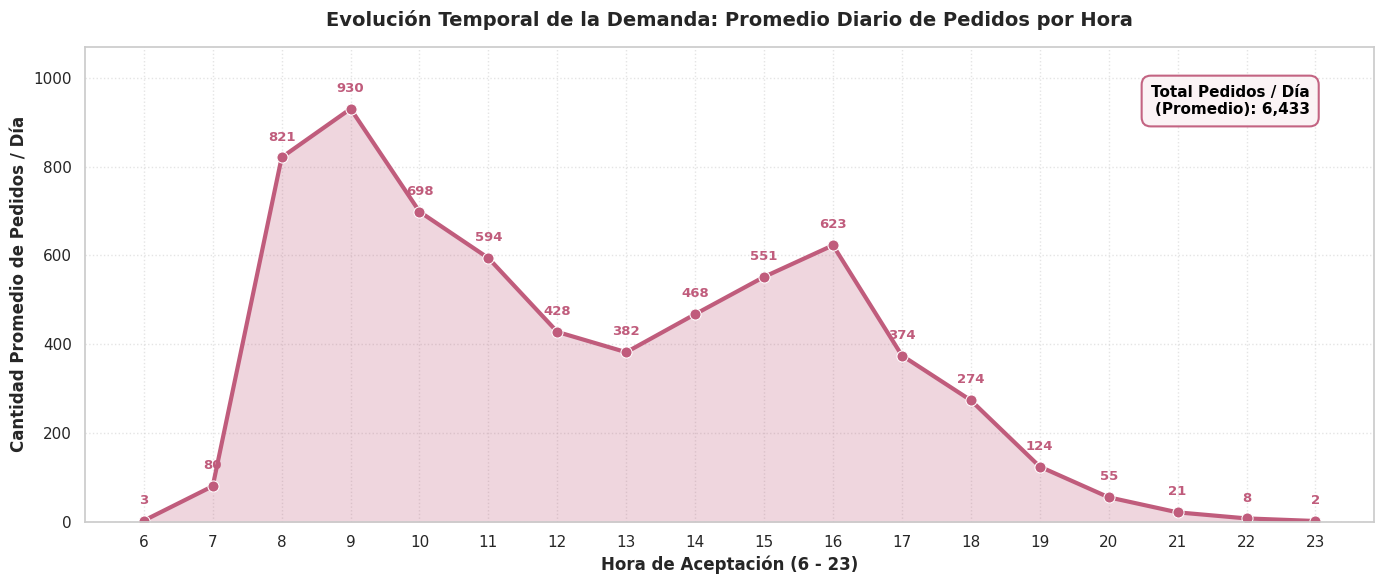

In [ ]:
# 2. Agrupamos originalmente por hora para contar el total histórico de pedidos
pedidos_por_hora = df4.groupby('accept_hour')['order_id'].count().reset_index()

# 3. FORZAMOS LAS 24 HORAS: Cruzamos con un rango completo de 6 a 23
horas_completas = pd.DataFrame({'accept_hour': range(6, 24)})
pedidos_por_hora = pd.merge(horas_completas, pedidos_por_hora, on='accept_hour', how='left')

# 4. Rellenamos las horas vacías con 0 y calculamos el promedio diario real
pedidos_por_hora['order_id'] = pedidos_por_hora['order_id'].fillna(0)
pedidos_por_hora['pedidos_promedio_dia'] = pedidos_por_hora['order_id'] / total_dias

# 5. CALCULAMOS EL TOTAL DIARIO PROMEDIO
total_diario_promedio = pedidos_por_hora['pedidos_promedio_dia'].sum()

# --- AJUSTE DE ESTILO (Fondo Blanco) ---
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))

# --- COLOR DE LA LÍNEA (Basado en tu gráfico de barras - Paleta 'flare') ---
color_linea = '#c05c7c'  # Tono central de la paleta flare/degradada que estás usando

# 6. Dibujamos la curva principal estilizada
sns.lineplot(
    data=pedidos_por_hora,
    x='accept_hour',
    y='pedidos_promedio_dia',
    marker='o',
    color=color_linea,
    linewidth=3,
    markersize=8,
    ax=ax
)

# --- REPLICAR SOMBREADO DE LA IMAGEN (Degradado bajo la curva) ---
# Rellenamos el área bajo la curva con una opacidad suave (alpha) para que el fondo blanco respire
ax.fill_between(
    pedidos_por_hora['accept_hour'],
    pedidos_por_hora['pedidos_promedio_dia'],
    color=color_linea,
    alpha=0.25
)

# 7. AGREGAMOS EL CARTEL INFORMATIVO ACTUALIZADO [cite: 1315]
texto_cartel = f"Total Pedidos / Día\n(Promedio): {int(total_diario_promedio):,}"
plt.text(
    0.95, 0.92,
    texto_cartel,
    transform=ax.transAxes,
    fontsize=11,
    fontweight='bold',
    color='black',
    ha='right',
    va='top',
    bbox=dict(
        boxstyle='round,pad=0.6',
        facecolor='#fbf3f5',  # Fondo sutil adaptado a la nueva paleta
        edgecolor=color_linea,
        linewidth=1.5,
        alpha=0.95
    )
)

# --- 8. AGREGAMOS LAS ETIQUETAS NUMÉRICAS EN CADA PUNTO  ---
for idx, fila in pedidos_por_hora.iterrows():
    hora = fila['accept_hour']
    promedio = fila['pedidos_promedio_dia']
    promedio_entero = int(round(promedio))

    if promedio_entero > 0:
        plt.annotate(
            f'{promedio_entero:,}',
            xy=(hora, promedio),
            xytext=(0, 10),           # Subimos un poco para que no choque con el punto
            textcoords="offset points",
            ha='center',
            va='bottom',
            fontsize=9.5,
            fontweight='bold',
            color=color_linea         # Sincronizado con el nuevo tono dominante
        )

# 9. Títulos y etiquetas del gráfico
plt.title('Evolución Temporal de la Demanda: Promedio Diario de Pedidos por Hora', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hora de Aceptación (6 - 23)', fontsize=12, fontweight='bold')
plt.ylabel('Cantidad Promedio de Pedidos / Día', fontsize=12, fontweight='bold')

# Estilizado de la cuadrícula de fondo para que luzca minimalista
ax.grid(True, linestyle=':', alpha=0.6, color='lightgray')
plt.xticks(range(6, 24))

# 15% de margen superior para asegurar espacio a las etiquetas
plt.ylim(0, pedidos_por_hora['pedidos_promedio_dia'].max() * 1.15)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Contamos el total general actual de la base de datos
total_general_pedidos = df4['order_id'].count()

# 2. Contamos los de las 6 a.m.
total_historico_6am = df4[df4['accept_hour'] == 6]['order_id'].count()

# 3. Calculamos el porcentaje
porcentaje_historico_6am = (total_historico_6am / total_general_pedidos) * 100

print("--- ANÁLISIS HISTÓRICO DE LAS 6:00 AM ---")
print(f"Pedidos a las 6:00 a.m.: {total_historico_6am:,} de un total de {total_general_pedidos:,}")
print(f"Porcentaje: {porcentaje_historico_6am:.2f}% del total histórico.")

--- ANÁLISIS HISTÓRICO DE LAS 6:00 AM ---
Pedidos a las 6:00 a.m.: 468 de un total de 1,183,836
Porcentaje: 0.04% del total histórico.


--- RENDIMIENTO DIARIO PROMEDIO (Calculado sobre 184 días únicos, desde las 6 AM) ---
 hora  promedio pedidos/día  demora media
    6                     3           5.4
    7                    80           2.3
    8                   821           2.2
    9                   930           2.6
   10                   698           2.1
   11                   594           1.6
   12                   428           1.5
   13                   382           1.5
   14                   468           1.4
   15                   551           1.4
   16                   623           1.4
   17                   374           1.2
   18                   274           1.0
   19                   124           1.0
   20                    55           1.0
   21                    21           0.7
   22                     8           0.5
   23                     2           0.4




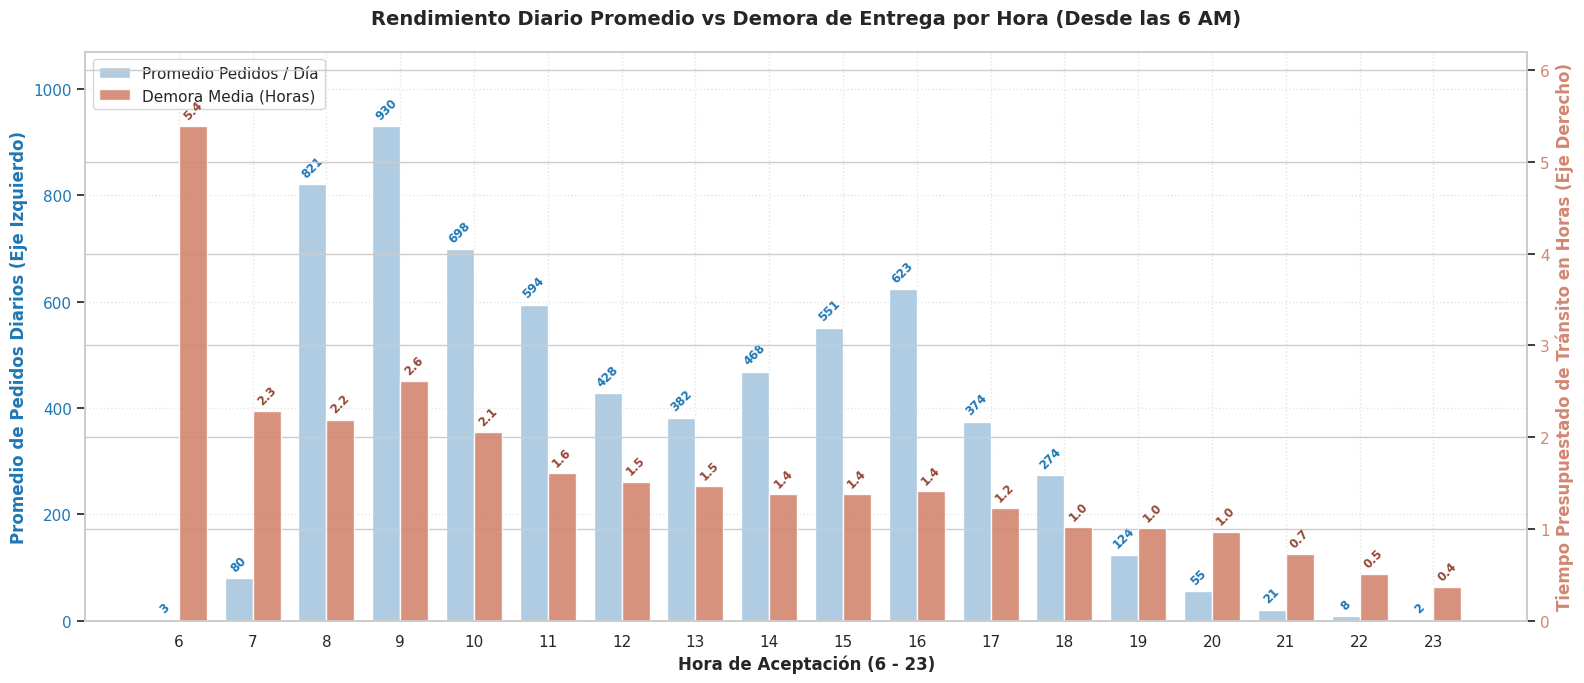

In [ ]:
# --- CALCULO DEL PROMEDIO DIARIO ---
# 1. Contamos cuántos días únicos reales existen en tu set de datos (columna 'ds')
total_dias_operacion = df4['ds'].nunique()

# 2. Agrupamos originalmente para obtener el conteo total histórico por hora
tabla_resumen = df4.groupby('accept_hour').agg(
    total_historico_pedidos=('order_id', 'count'),
    demora_media=('transit_time_hours', 'mean')
).reset_index()

# 3. Dividimos el total histórico entre los días de operación para sacar el promedio diario
tabla_resumen['cant_pedidos_dia'] = tabla_resumen['total_historico_pedidos'] / total_dias_operacion

# --- CORRECCIÓN DE HORAS Y FORMATOS (Empezando a las 6 AM) ---
# 4. Forzamos la estructura desde las 6 hasta las 23 horas (evitamos que vuelvan a aparecer las horas borradas)
horas_completas = pd.DataFrame({'accept_hour': range(6, 24)})
tabla_resumen = pd.merge(horas_completas, tabla_resumen, on='accept_hour', how='left')

# 5. Rellenamos vacíos y convertimos el promedio de pedidos a ENTERO redondeado (.round())
tabla_resumen['cant_pedidos_dia'] = tabla_resumen['cant_pedidos_dia'].fillna(0).round().astype(int)
tabla_resumen['demora_media'] = tabla_resumen['demora_media'].fillna(0.0)

# Renombramos las columnas para tu reporte escrito en pantalla
tabla_resumen_print = tabla_resumen[['accept_hour', 'cant_pedidos_dia', 'demora_media']].rename(columns={
    'accept_hour': 'hora',
    'cant_pedidos_dia': 'promedio pedidos/día',
    'demora_media': 'demora media'
})

# 6. IMPRIMIMOS LA TABLA EN PANTALLA
print(f"--- RENDIMIENTO DIARIO PROMEDIO (Calculado sobre {total_dias_operacion} días únicos, desde las 6 AM) ---")
pd.options.display.float_format = '{:.1f}'.format
print(tabla_resumen_print.to_string(index=False))
print("\n" + "="*60 + "\n")


# --- 7. CONFIGURACIÓN Y GENERACIÓN DEL GRÁFICO ---
sns.set_theme(style="whitegrid")  # Forzamos fondo blanco limpio con cuadrículas suaves
fig, ax1 = plt.subplots(figsize=(16, 7))
width = 0.38

# Barras Izquierdas: Promedio Diario de Pedidos (Eje Y Izquierdo)
color_pedidos = '#afcce3'  # Mantiene el celeste pastel limpio
barras_pedidos = ax1.bar(
    tabla_resumen['accept_hour'] - width/2,
    tabla_resumen['cant_pedidos_dia'],
    width=width,
    color=color_pedidos,
    label='Promedio Pedidos / Día'
)
ax1.set_xlabel('Hora de Aceptación (6 - 23)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Promedio de Pedidos Diarios (Eje Izquierdo)', color='#1f77b4', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.set_xticks(range(6, 24))
ax1.grid(True, linestyle=':', alpha=0.6, color='lightgray')  # Cuadrícula minimalista

# =====================================================================
# 🛠️ CAMBIO SUTIL DE PALETA: El nuevo color extraído de tu imagen
# =====================================================================
ax2 = ax1.twinx()
color_demora = '#d38670'  # El elegante tono terracota/salmón opaco de tu captura

barras_demora = ax2.bar(
    tabla_resumen['accept_hour'] + width/2,
    tabla_resumen['demora_media'],
    width=width,
    color=color_demora,
    alpha=0.9,               # Un toque más de opacidad para consolidar el color de relleno
    label='Demora Media (Horas)'
)
ax2.set_ylabel('Tiempo Presupuestado de Tránsito en Horas (Eje Derecho)', color=color_demora, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_demora)


# --- 8. AGREGAMOS LAS ETIQUETAS NUMÉRICAS ---

# Etiquetas para las barras de Pedidos
for barra in barras_pedidos:
    altura = barra.get_height()
    if altura > 0:
        ax1.annotate(
            f'{int(altura):,}',
            xy=(barra.get_x() + barra.get_width() / 2, altura),
            xytext=(0, 3),
            textcoords="offset points",
            ha='center',
            va='bottom',
            fontsize=8.5,
            color='#1f77b4',
            fontweight='bold',
            rotation=45
        )

# Etiquetas para las barras de Demora Media
for barra in barras_demora:
    altura = barra.get_height()
    if altura > 0:
        ax2.annotate(
            f'{altura:.1f}',
            xy=(barra.get_x() + barra.get_width() / 2, altura),
            xytext=(0, 3),
            textcoords="offset points",
            ha='center',
            va='bottom',
            fontsize=8.5,
            color='#934835',  # Un tono marrón/vino derivado del salmón para que sea legible al leer
            fontweight='bold',
            rotation=45
        )

# Combinamos las leyendas en la esquina superior izquierda
elementos_leyenda = [barras_pedidos, barras_demora]
etiquetas_leyenda = [b.get_label() for b in elementos_leyenda]
ax1.legend(elementos_leyenda, etiquetas_leyenda, loc='upper left', fontsize=11)

# Ajustamos márgenes superiores (15% de holgura)
ax1.set_ylim(0, tabla_resumen['cant_pedidos_dia'].max() * 1.15)
ax2.set_ylim(0, tabla_resumen['demora_media'].max() * 1.15)

plt.title('Rendimiento Diario Promedio vs Demora de Entrega por Hora (Desde las 6 AM)', fontsize=14, fontweight='bold', pad=20)
fig.tight_layout()

# Guardamos el archivo final optimizado
plt.savefig("reporte_promedio_diario.png", dpi=300)
plt.show()

In [ ]:
# 1. Contamos la cantidad de días únicos reales en la columna 'ds' (tu divisor general)
total_dias = df4['ds'].nunique()

# 2. CALCULAMOS EL PROMEDIO DIARIO: Contamos couriers únicos por cada DIA y HORA individual
couriers_por_dia_hora = df4.groupby(['ds', 'accept_hour']).agg(
    couriers_unicos_ese_dia=('courier_id', 'nunique')
).reset_index()

# Sumamos esos conteos diarios por hora y los dividimos entre el total de días reales
promedio_couriers_por_hora = couriers_por_dia_hora.groupby('accept_hour').agg(
    promedio_couriers_diarios=('couriers_unicos_ese_dia', 'sum')
).reset_index()
promedio_couriers_por_hora['promedio_couriers_diarios'] = promedio_couriers_por_hora['promedio_couriers_diarios'] / total_dias

# 3. METRICAS BASE: Agrupamos df4 por hora para obtener tiempo medio y couriers históricos acumulados
tabla_base = df4.groupby('accept_hour').agg(
    tiempo_medio=('transit_time_hours', 'mean'),
    couriers_historicos_totales=('courier_id', 'nunique')
).reset_index()

# 4. UNIFICACIÓN: Unimos los datos base con la nueva columna de promedios diarios
tabla_flota = pd.merge(tabla_base, promedio_couriers_por_hora, on='accept_hour', how='left')

# 5. FILTRO CRÍTICO: Eliminamos por completo las horas de la 0 a la 5
tabla_flota = tabla_flota[tabla_flota['accept_hour'] >= 6].copy()

# 6. LIMPIEZA DE FORMATOS: Rellenamos vacíos y convertimos a tipos de datos limpios
tabla_flota['tiempo_medio'] = tabla_flota['tiempo_medio'].fillna(0.0)
tabla_flota['couriers_historicos_totales'] = tabla_flota['couriers_historicos_totales'].fillna(0).astype(int)
tabla_flota['promedio_couriers_diarios'] = tabla_flota['promedio_couriers_diarios'].fillna(0).round().astype(int)

# 7. METAMORFOSIS DE COLUMNAS: Renombramos exactamente al formato final que necesitas
tabla_flota = tabla_flota.rename(columns={
    'accept_hour': 'hora',
    'tiempo_medio': 'tiempo medio accept-delivery',
    'couriers_historicos_totales': 'couriers históricos únicos',
    'promedio_couriers_diarios': 'promedio couriers activos/día'
})

# 8. CONFIGURACIÓN DE IMPRESIÓN: 1 solo decimal para el tiempo y visualización en pantalla
pd.options.display.float_format = '{:.1f}'.format

print(f"--- RECONSTRUCCIÓN DE TABLA DE FLOTA (Zona Activa: 6-23h | {total_dias} días evaluados) ---")
print(tabla_flota.to_string(index=False))

--- RECONSTRUCCIÓN DE TABLA DE FLOTA (Zona Activa: 6-23h | 184 días evaluados) ---
 hora  tiempo medio accept-delivery  couriers históricos únicos  promedio couriers activos/día
    6                           5.4                          40                              1
    7                           2.3                         270                             17
    8                           2.2                         363                            112
    9                           2.6                         363                            128
   10                           2.1                         363                            115
   11                           1.6                         363                            108
   12                           1.5                         363                             86
   13                           1.5                         363                             82
   14                           1.4                         36

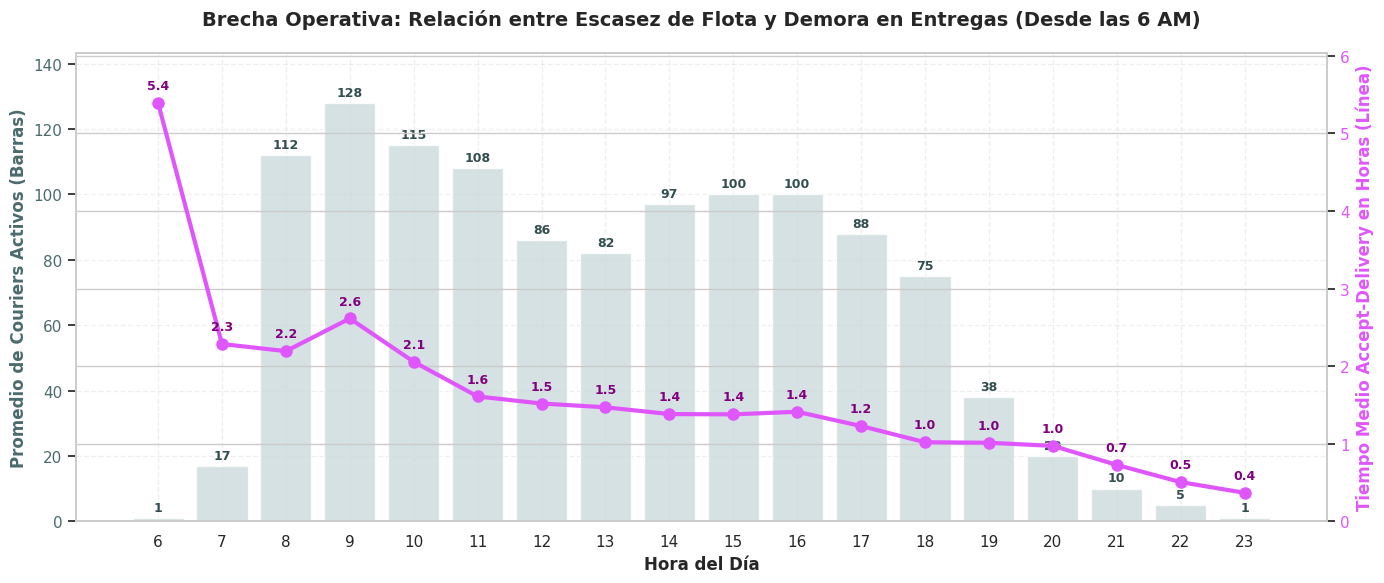

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Usamos directamente la tabla que reconstruiste (ya viene limpia desde la hora 6)
df_grafico = tabla_flota.copy()

fig, ax1 = plt.subplots(figsize=(14, 6))

# --- EJE 1 (Izquierdo): Flota promedio disponible ---
color_flota = '#cbdadb'  # Gris azulado neutro para el fondo
ax1.bar(
    df_grafico['hora'],
    df_grafico['promedio couriers activos/día'],  # CORREGIDO
    color=color_flota,
    alpha=0.8,
    label='Promedio Couriers Activos / Día'
)
ax1.set_xlabel('Hora del Día', fontsize=12, fontweight='bold')
ax1.set_ylabel('Promedio de Couriers Activos (Barras)', color='#4a6b6c', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#4a6b6c')
ax1.set_xticks(range(6, 24))
ax1.grid(True, linestyle='--', alpha=0.3)

# Agregar etiquetas de texto encima de las barras de couriers promedio
for index, row in df_grafico.iterrows():
    altura_barra = row['promedio couriers activos/día']
    ax1.text(
        row['hora'],
        altura_barra + (tabla_flota['promedio couriers activos/día'].max() * 0.01), # Desfase dinámico hacia arriba
        f"{int(altura_barra)}",
        ha='center',
        va='bottom',
        fontsize=9,
        color='#334e4f',
        fontweight='bold'
    )

# --- EJE 2 (Derecho): Tiempo de demora promedio ---
ax2 = ax1.twinx()
color_tiempo = '#e056fd'  # El color magenta intenso para la línea de retraso
ax2.plot(
    df_grafico['hora'],
    df_grafico['tiempo medio accept-delivery'],  # CORREGIDO
    color=color_tiempo,
    marker='o',
    linewidth=3,
    markersize=8,
    label='Tiempo Medio'
)
ax2.set_ylabel('Tiempo Medio Accept-Delivery en Horas (Línea)', color=color_tiempo, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_tiempo)

# Agregar etiquetas de texto a los puntos de la línea de tiempo
for index, row in df_grafico.iterrows():
    valor_tiempo = row['tiempo medio accept-delivery']
    ax2.annotate(
        f"{valor_tiempo:.1f}",
        xy=(row['hora'], valor_tiempo),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center',
        fontsize=9,
        color='purple',
        fontweight='bold'
    )

# Ajustamos márgenes superiores para que las etiquetas no se peguen al techo
ax1.set_ylim(0, df_grafico['promedio couriers activos/día'].max() * 1.12)
ax2.set_ylim(0, df_grafico['tiempo medio accept-delivery'].max() * 1.12)

plt.title('Brecha Operativa: Relación entre Escasez de Flota y Demora en Entregas (Desde las 6 AM)', fontsize=14, fontweight='bold', pad=20)
fig.tight_layout()
plt.show()

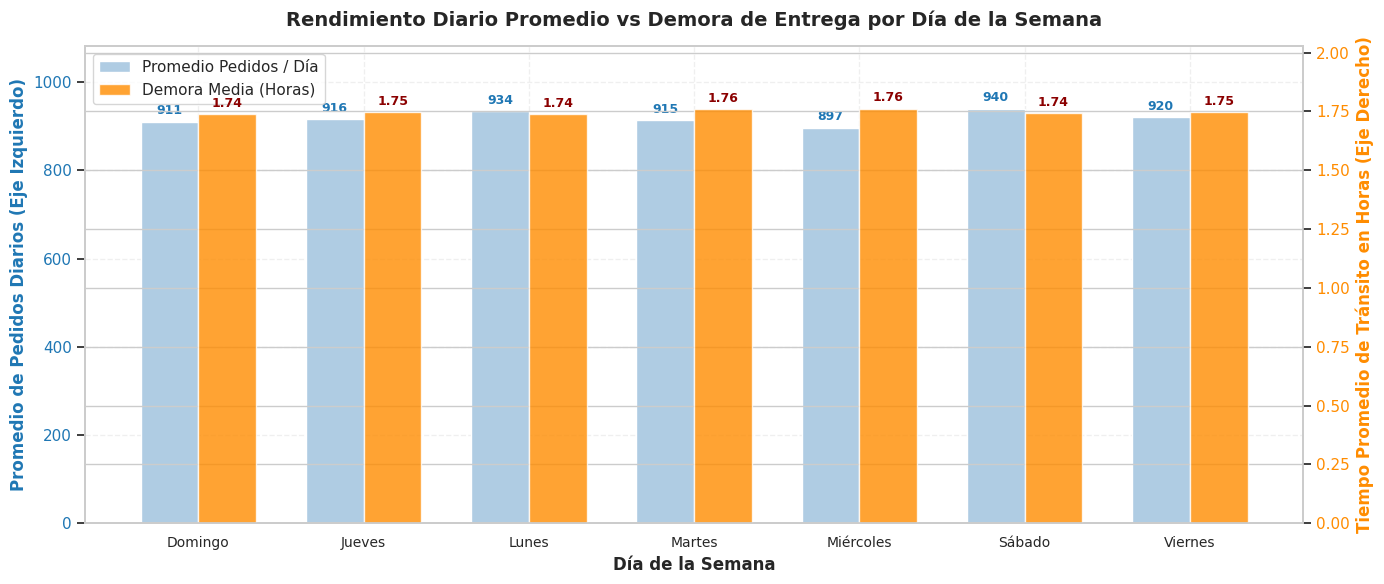

In [ ]:
# 1. Agrupación de datos por día de la semana
total_dias_operacion = df4['ds'].nunique()

tabla_resumen_semana = df4.groupby('accept_weekday', observed=False).agg(
    total_historico_pedidos=('order_id', 'count'),
    demora_media=('transit_time_hours', 'mean')
).reset_index()

# Calculamos el promedio diario real para cada día de la semana
tabla_resumen_semana['cant_pedidos_dia'] = tabla_resumen_semana['total_historico_pedidos'] / total_dias_operacion

# 2. Inicialización del lienzo para el gráfico de barras dobles
fig, ax1 = plt.subplots(figsize=(14, 6))
width = 0.35

# Eje Y Izquierdo: Promedio de Pedidos Diarios (Barras Celestes)
color_pedidos = '#afcce3'
barras_pedidos = ax1.bar(
    tabla_resumen_semana.index - width/2,
    tabla_resumen_semana['cant_pedidos_dia'],
    width=width,
    color=color_pedidos,
    label='Promedio Pedidos / Día'
)

ax1.set_xlabel('Día de la Semana', fontsize=12, fontweight='bold')
ax1.set_ylabel('Promedio de Pedidos Diarios (Eje Izquierdo)', color='#1f77b4', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.set_xticks(range(len(tabla_resumen_semana)))
ax1.set_xticklabels(tabla_resumen_semana['accept_weekday'], fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.3)

# Eje Y Derecho: Demora Media en Horas (Barras Naranjas)
ax2 = ax1.twinx()
color_demora = 'darkorange'
barras_demora = ax2.bar(
    tabla_resumen_semana.index + width/2,
    tabla_resumen_semana['demora_media'],
    width=width,
    color=color_demora,
    alpha=0.8,
    label='Demora Media (Horas)'
)

ax2.set_ylabel('Tiempo Promedio de Tránsito en Horas (Eje Derecho)', color='darkorange', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='darkorange')

# 3. Incorporación de etiquetas numéricas sobre las barras
for barra in barras_pedidos:
    altura = barra.get_height()
    if altura > 0:
        ax1.annotate(f'{int(round(altura)):,}',
                     xy=(barra.get_x() + barra.get_width() / 2, altura),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, color='#1f77b4', fontweight='bold')

for barra in barras_demora:
    altura = barra.get_height()
    if altura > 0:
        ax2.annotate(f'{altura:.2f}',
                     xy=(barra.get_x() + barra.get_width() / 2, altura),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, color='darkred', fontweight='bold')

# Combinación de leyendas y ajustes finales
elementos_leyenda = [barras_pedidos, barras_demora]
etiquetas_leyenda = [b.get_label() for b in elementos_leyenda]
ax1.legend(elementos_leyenda, etiquetas_leyenda, loc='upper left', fontsize=11)

ax1.set_ylim(0, tabla_resumen_semana['cant_pedidos_dia'].max() * 1.15)
ax2.set_ylim(0, tabla_resumen_semana['demora_media'].max() * 1.15)

plt.title('Rendimiento Diario Promedio vs Demora de Entrega por Día de la Semana', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.savefig("reporte_promedio_semanal.png", dpi=300)
plt.show()

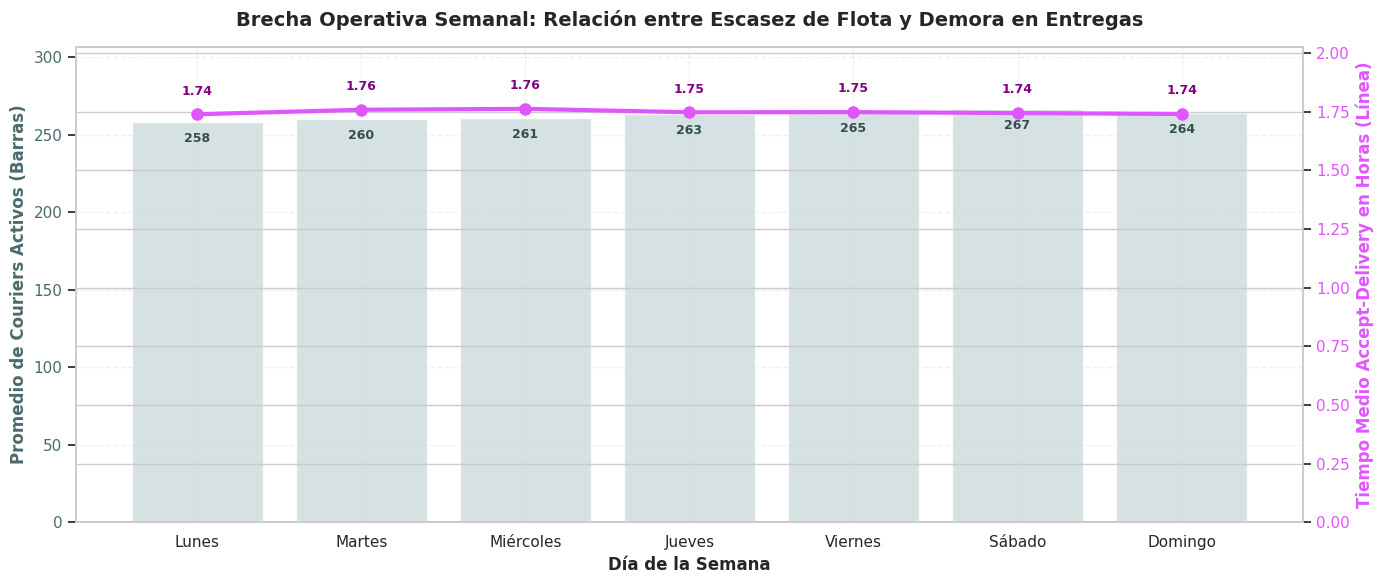

In [ ]:
# 1. Replicamos la lógica de unificación de la flota
dias_unicos_calendario = df4.groupby('accept_weekday', observed=False)['ds'].nunique().reset_index()
dias_unicos_calendario = dias_unicos_calendario.rename(columns={'ds': 'total_dias_reales'})

couriers_por_fecha_semana = df4.groupby(['ds', 'accept_weekday'], observed=False).agg(
    couriers_ese_dia=('courier_id', 'nunique')
).reset_index()

promedio_couriers_semana = couriers_por_fecha_semana.groupby('accept_weekday', observed=False).agg(
    suma_couriers=('couriers_ese_dia', 'sum')
).reset_index()

tabla_flota_semana = pd.merge(promedio_couriers_semana, dias_unicos_calendario, on='accept_weekday', how='left')
tabla_flota_semana['promedio_couriers_activos'] = tabla_flota_semana['suma_couriers'] / tabla_flota_semana['total_dias_reales']

tabla_base_semana = df4.groupby('accept_weekday', observed=False).agg(
    tiempo_medio=('transit_time_hours', 'mean')
).reset_index()

df_grafico_semana = pd.merge(tabla_base_semana, tabla_flota_semana[['accept_weekday', 'promedio_couriers_activos']], on='accept_weekday', how='left')

orden_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
df_grafico_semana['accept_weekday'] = pd.Categorical(df_grafico_semana['accept_weekday'], categories=orden_dias, ordered=True)
df_grafico_semana = df_grafico_semana.sort_values('accept_weekday').reset_index(drop=True)


# 2. Construcción del Lienzo de la Brecha Operativa Semanal
fig, ax1 = plt.subplots(figsize=(14, 6))

# Eje 1 (Izquierdo): Flota promedio disponible (Barras Grises)
color_flota = '#cbdadb'
ax1.bar(
    df_grafico_semana['accept_weekday'],
    df_grafico_semana['promedio_couriers_activos'],
    color=color_flota,
    alpha=0.8,
    label='Promedio Couriers Activos / Día'
)

ax1.set_xlabel('Día de la Semana', fontsize=12, fontweight='bold')
ax1.set_ylabel('Promedio de Couriers Activos (Barras)', color='#4a6b6c', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#4a6b6c')
ax1.grid(True, linestyle='--', alpha=0.3)

# =====================================================================
# 🛠️ CORRECCIÓN AQUÍ: Bajamos las etiquetas modificando la coordenada Y
# =====================================================================
for index, row in df_grafico_semana.iterrows():
    altura_barra = row['promedio_couriers_activos']
    # Restamos un 4% del valor máximo para que el texto se meta de forma prolija dentro de la barra
    desfase_y = df_grafico_semana['promedio_couriers_activos'].max() * 0.04

    ax1.text(
        index,
        altura_barra - desfase_y,  # Posición Y corregida matemáticamente
        f"{int(round(altura_barra))}",
        ha='center',
        va='center',               # Centramos el texto relativo a su nueva posición
        fontsize=9,
        color='#334e4f',
        fontweight='bold'
    )

# Eje 2 (Derecho): Tiempo de demora promedio (Línea Magenta)
ax2 = ax1.twinx()
color_tiempo = '#e056fd'
ax2.plot(
    df_grafico_semana['accept_weekday'],
    df_grafico_semana['tiempo_medio'],
    color=color_tiempo,
    marker='o',
    linewidth=3,
    markersize=8,
    label='Tiempo Medio'
)
ax2.set_ylabel('Tiempo Medio Accept-Delivery en Horas (Línea)', color=color_tiempo, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_tiempo)

# Etiquetas de texto a los puntos de la línea de tiempo (Usando annotate de forma correcta)
for index, row in df_grafico_semana.iterrows():
    valor_tiempo = row['tiempo_medio']
    ax2.annotate(
        f"{valor_tiempo:.2f}",
        xy=(index, valor_tiempo),
        xytext=(0, 12),    # Holgura de 12 puntos hacia arriba del punto magenta
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=9,
        color='purple',
        fontweight='bold'
    )

# Holguras para los techos del lienzo gráfico
ax1.set_ylim(0, df_grafico_semana['promedio_couriers_activos'].max() * 1.15)
ax2.set_ylim(0, df_grafico_semana['tiempo_medio'].max() * 1.15)

plt.title('Brecha Operativa Semanal: Relación entre Escasez de Flota y Demora en Entregas', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

# **5. KPI: Rendimiento Geográfico - Zonas Críticas**
Qué mide: El éxito o fricción logísctica dependiendo de las regiones de la ciudad de Shanghái. ¿En qué zonas se concentran las demoras? Utilizando region_id

In [ ]:
# ¿En qué zonas se concentran las demoras?

# 1. Métricas de demora por zona
df_zonas = (
    df_ftt.groupby(['region_id', 'aoi_id', 'aoi_type'])
    .agg(
        transit_time_promedio = ('transit_time', 'mean'),
        transit_time_mediana  = ('transit_time', 'median'),
        total_pedidos         = ('transit_time', 'count'),
        pct_mayor_24h         = ('transit_time', lambda x: (x > 1440).mean() * 100)
    )
    .reset_index()
    .sort_values('transit_time_promedio', ascending=False)
)

print("Top 10 zonas con MAYOR tiempo promedio de tránsito (en minutos):")
display(df_zonas.head(10))

print("\nTop 10 zonas con MENOR tiempo promedio de tránsito (en minutos):")
display(df_zonas.tail(10))

Top 10 zonas con MAYOR tiempo promedio de tránsito (en minutos):


,region_id,aoi_id,aoi_type,transit_time_promedio,transit_time_mediana,total_pedidos,pct_mayor_24h
13883,84,10150,0,1388.0,1388.0,1,0.0
9010,52,49332,14,908.0,908.0,1,0.0
12604,77,4405,14,887.0,887.0,1,0.0
8813,52,33756,14,797.0,797.0,2,0.0
986,6,20794,14,789.1,547.0,25,0.0
11883,71,49297,14,778.0,778.0,1,0.0
8678,52,24089,14,775.0,775.0,1,0.0
7115,45,6864,4,767.0,767.0,2,0.0
7578,45,57123,5,767.0,767.0,1,0.0
2365,9,58375,14,751.0,751.0,1,0.0



Top 10 zonas con MENOR tiempo promedio de tránsito (en minutos):


,region_id,aoi_id,aoi_type,transit_time_promedio,transit_time_mediana,total_pedidos,pct_mayor_24h
5482,38,11949,4,1.0,1.0,1,0.0
1622,9,9712,1,1.0,1.0,1,0.0
13591,80,31626,14,1.0,1.0,1,0.0
9412,54,37929,14,1.0,1.0,1,0.0
1931,9,28253,14,1.0,1.0,1,0.0
3106,17,19865,14,1.0,1.0,1,0.0
7984,50,20387,1,1.0,1.0,1,0.0
9576,57,6695,7,1.0,1.0,1,0.0
5,1,815,14,1.0,1.0,1,0.0
8928,52,42739,2,1.0,1.0,2,0.0


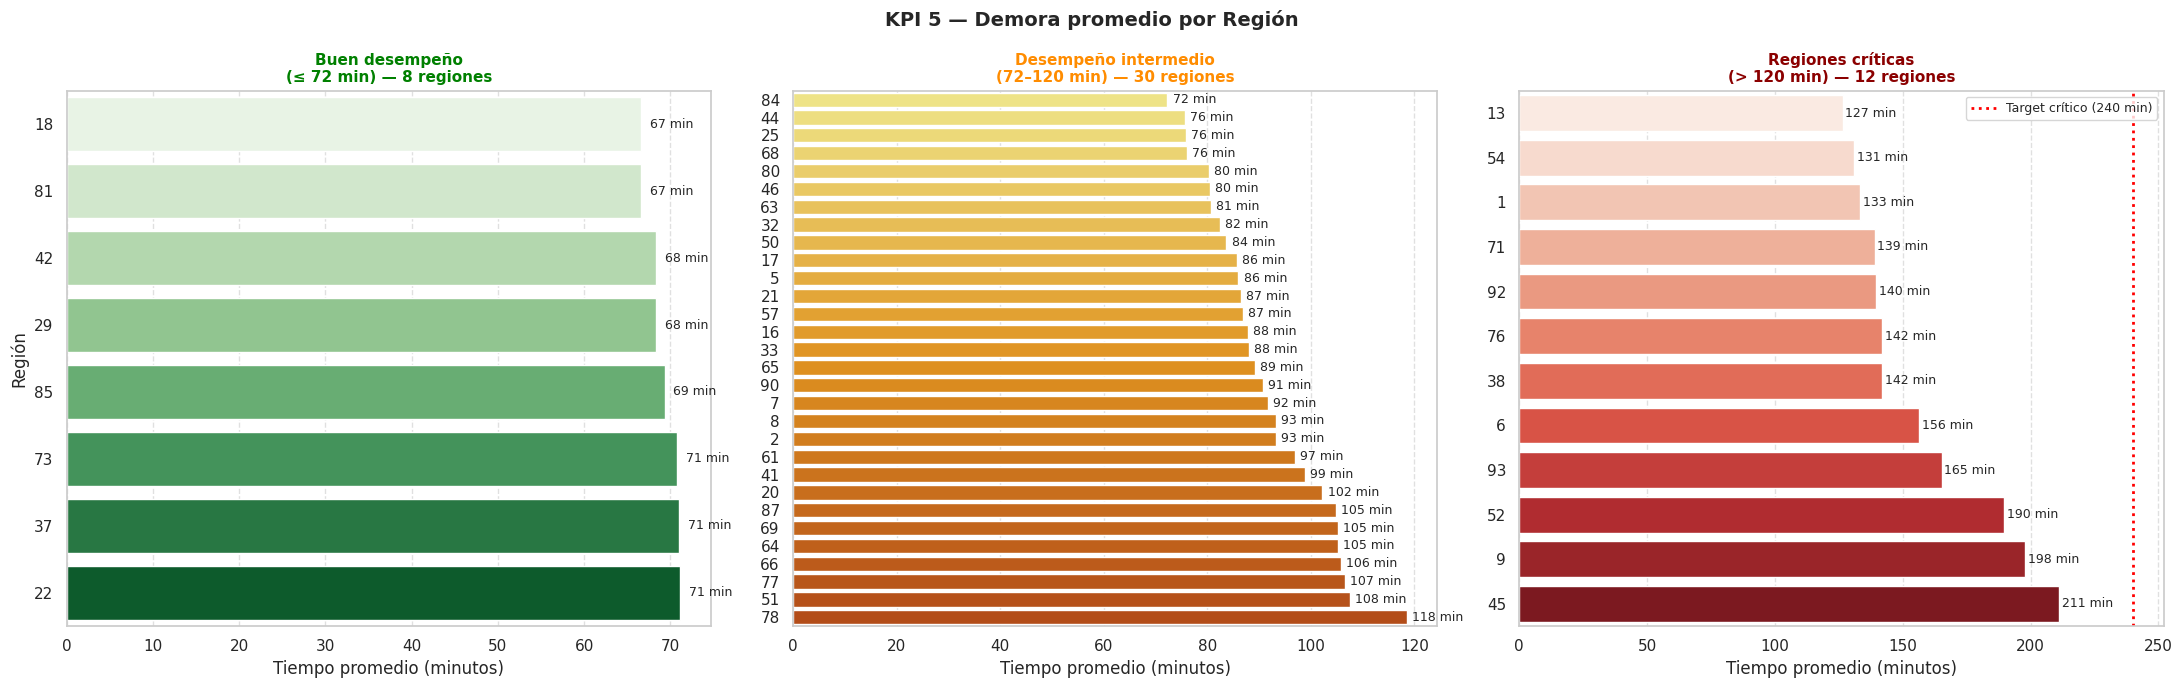

In [ ]:
# Preparar datos de región
demora_por_region = (df.groupby('region_id')['transit_time']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)
demora_por_region['region_id'] = demora_por_region['region_id'].astype(str)

# Separar en tres grupos
regiones_buenas   = demora_por_region[demora_por_region['transit_time'] <= 72].sort_values('transit_time', ascending=True)
regiones_medias   = demora_por_region[(demora_por_region['transit_time'] > 72) & (demora_por_region['transit_time'] <= 120)].sort_values('transit_time', ascending=True)
regiones_criticas = demora_por_region[demora_por_region['transit_time'] > 120].sort_values('transit_time', ascending=True)

# Paleta de colores para intermedias: naranja oscuro a naranja a amarillo claro
palette_medias = sns.blend_palette(
    ["#FFF176", "#FF9900", "#CC4400"],
    n_colors=len(regiones_medias)
)

# Armado de gráfico con 3 paneles
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 7))
fig.suptitle('KPI 5 — Demora promedio por Región', fontsize=14, fontweight='bold')

# a. GRÁFICO IZQUIERDO: ≤ 72 min (mejores)
sns.barplot(
    data=regiones_buenas,
    x='transit_time',
    y='region_id',
    hue='region_id',
    legend=False,
    orient='h',
    palette='Greens',
    ax=ax1,
    order=regiones_buenas['region_id']
)
ax1.set_title(f'Buen desempeño\n(≤ 72 min) — {len(regiones_buenas)} regiones',
              fontsize=11, fontweight='bold', color='green')
ax1.set_xlabel('Tiempo promedio (minutos)')
ax1.set_ylabel('Región')
ax1.grid(axis='x', linestyle='--', alpha=0.6)
for patch, val in zip(ax1.patches, regiones_buenas['transit_time']):
    ax1.text(val + 1, patch.get_y() + patch.get_height() / 2,
             f'{val:.0f} min', va='center', fontsize=9)

# b. GRÁFICO CENTRAL: > 72 y ≤ 120 min (intermedias)
sns.barplot(
    data=regiones_medias,
    x='transit_time',
    y='region_id',
    hue='region_id',
    legend=False,
    orient='h',
    palette=palette_medias,
    ax=ax2,
    order=regiones_medias['region_id']
)
ax2.set_title(f'Desempeño intermedio\n(72–120 min) — {len(regiones_medias)} regiones',
              fontsize=11, fontweight='bold', color='darkorange')
ax2.set_xlabel('Tiempo promedio (minutos)')
ax2.set_ylabel('')
ax2.grid(axis='x', linestyle='--', alpha=0.6)
for patch, val in zip(ax2.patches, regiones_medias['transit_time']):
    ax2.text(val + 1, patch.get_y() + patch.get_height() / 2,
             f'{val:.0f} min', va='center', fontsize=9)

# C. GRÁFICO DERECHO: > 120 min (críticas) ---
sns.barplot(
    data=regiones_criticas,
    x='transit_time',
    y='region_id',
    hue='region_id',
    legend=False,
    orient='h',
    palette='Reds',
    ax=ax3,
    order=regiones_criticas['region_id']
)
ax3.set_title(f'Regiones críticas\n(> 120 min) — {len(regiones_criticas)} regiones',
              fontsize=11, fontweight='bold', color='darkred')
ax3.set_xlabel('Tiempo promedio (minutos)')
ax3.set_ylabel('')
ax3.axvline(240, color='red', linestyle=':', linewidth=2,
            label='Target crítico (240 min)')
ax3.legend(fontsize=9)
ax3.grid(axis='x', linestyle='--', alpha=0.6)
for patch, val in zip(ax3.patches, regiones_criticas['transit_time']):
    ax3.text(val + 1, patch.get_y() + patch.get_height() / 2,
             f'{val:.0f} min', va='center', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# 3. Mapa de calor: Zonas críticas
# Usamos las coordenadas de entrega (delivery_gps) ponderadas por transit_time

# Preparar datos: coordenada de entrega + transit_time como peso
df_mapa = df[['delivery_gps_lat', 'delivery_gps_lng', 'transit_time']].dropna()

# Coordenadas centrales de Shanghai
lat_centro = df_mapa['delivery_gps_lat'].mean()
lng_centro = df_mapa['delivery_gps_lng'].mean()

mapa_kpi5 = folium.Map(
    location=[lat_centro, lng_centro],
    zoom_start=12,
)

# Datos para el heatmap: [lat, lng, transit_time]
heat_data = df_mapa[['delivery_gps_lat', 'delivery_gps_lng', 'transit_time']].values.tolist()

HeatMap(
    heat_data,
    min_opacity=0.3,
    max_zoom=15,
    radius=12,
    blur=10,
    gradient={0.2: 'green', 0.5: 'yellow', 0.8: 'orange', 0.95: 'red'}
).add_to(mapa_kpi5)
mapa_kpi5

Output hidden; open in https://colab.research.google.com to view.

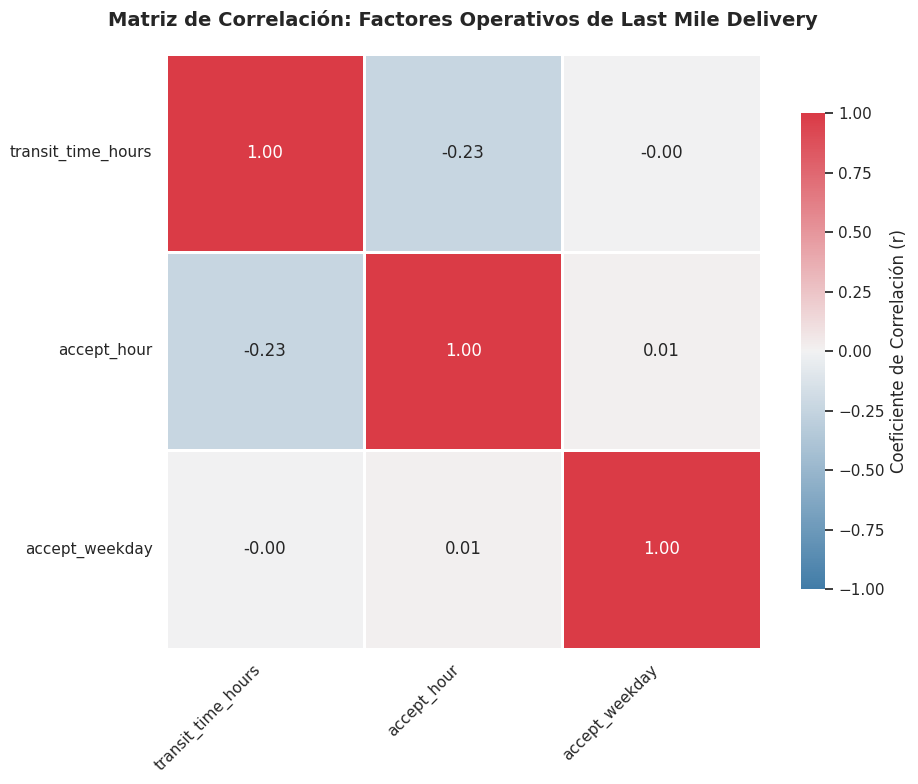

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Creamos una copia temporal para no alterar tu DataFrame original 'df4'
df_corr = df4.copy()

# 2. Si 'accept_weekday' tiene los nombres de los días, los transformamos a números
if "accept_weekday" in df_corr.columns and df_corr["accept_weekday"].dtype == "object":
    dias_mapeo = {
        "Lunes": 0,
        "Martes": 1,
        "Miércoles": 2,
        "Miercoles": 2,  # Por si las dudas con el tilde
        "Jueves": 3,
        "Viernes": 4,
        "Sábado": 5,
        "Sabado": 5,
        "Domingo": 6,
    }
    df_corr["accept_weekday"] = df_corr["accept_weekday"].map(dias_mapeo)

# 3. Definimos las variables numéricas de interés
variables_interes = [
    "transit_time_hours",
    "dist_km",
    "ratio_minkm",
    "accept_hour",
    "accept_weekday",
]

# 4. Filtramos solo las columnas que existan en el DataFrame
columnas_validas = [col for col in variables_interes if col in df_corr.columns]

# 5. Calculamos la matriz de correlación de Pearson directamente sobre los datos numéricos limpia
matriz_corr = df_corr[columnas_validas].corr()

# 6. Configuramos y dibujamos el mapa de calor
plt.figure(figsize=(10, 8))
cmap_personalizado = sns.diverging_palette(240, 10, as_cmap=True)

sns.heatmap(
    matriz_corr,
    annot=True,              # Muestra los coeficientes numéricos
    cmap=cmap_personalizado,  # Paleta de azul a rojo pasando por blanco
    fmt=".2f",               # Redondeo a 2 decimales
    linewidths=0.8,          # Separación elegante entre celdas
    vmin=-1,                 # Mínimo valor de correlación
    vmax=1,                  # Máximo valor de correlación
    square=True,             # Celdas perfectamente cuadradas
    cbar_kws={"label": "Coeficiente de Correlación (r)", "shrink": 0.8},
)

plt.title(
    "Matriz de Correlación: Factores Operativos de Last Mile Delivery",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xticks(rotation=45, ha="right", fontsize=11)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()
plt.show()

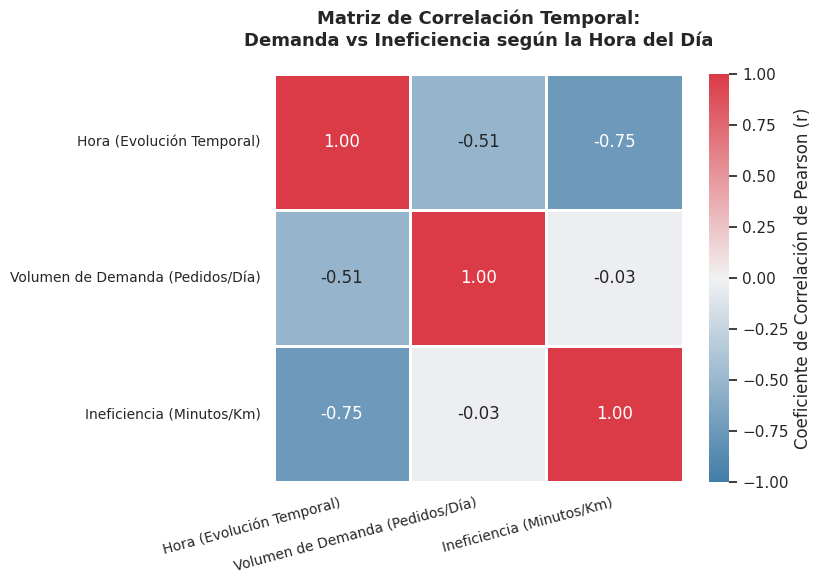

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Traemos la métrica de rendimiento al DataFrame df4
df4["ratio_minkm"] = df["ratio_minkm"]

# 2. Obtenemos el total de días únicos para estandarizar el volumen de pedidos
total_dias_operacion = df4["ds"].nunique()

# 3. Agrupamos por hora para consolidar el comportamiento del sistema
# Convertimos el ratio a MINUTOS por kilómetro (dividiendo por 60 los segundos)
df_perfil_horario = (
    df4.groupby("accept_hour")
    .agg(
        pedidos_totales=("order_id", "count"),
        eficiencia_minkm=("ratio_minkm", lambda x: x.mean() / 60),
    )
    .reset_index()
)

# Calculamos el promedio diario de pedidos por hora
df_perfil_horario["pedidos_promedio_dia"] = (
    df_perfil_horario["pedidos_totales"] / total_dias_operacion
)

# 4. Seleccionamos las variables numéricas que queremos correlacionar temporalmente
# Cambiamos el nombre de accept_hour a 'Momento del Día' para que el gráfico sea más intuitivo
df_analisis = df_perfil_horario[
    ["accept_hour", "pedidos_promedio_dia", "eficiencia_minkm"]
].rename(
    columns={
        "accept_hour": "Hora (Evolución Temporal)",
        "pedidos_promedio_dia": "Volumen de Demanda (Pedidos/Día)",
        "eficiencia_minkm": "Ineficiencia (Minutos/Km)",
    }
)

# 5. Calculamos la matriz de correlación sobre el perfil horario
matriz_temporal = df_analisis.corr()

# 6. Graficamos el Heatmap
plt.figure(figsize=(8, 6))
sns.set_theme(style="white")

cmap_divergente = sns.diverging_palette(240, 10, as_cmap=True)

sns.heatmap(
    matriz_temporal,
    annot=True,
    cmap=cmap_divergente,
    fmt=".2f",
    linewidths=1,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"label": "Coeficiente de Correlación de Pearson (r)"},
)

plt.title(
    "Matriz de Correlación Temporal:\nDemanda vs Ineficiencia según la Hora del Día",
    fontsize=13,
    fontweight="bold",
    pad=20,
)
plt.xticks(rotation=15, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

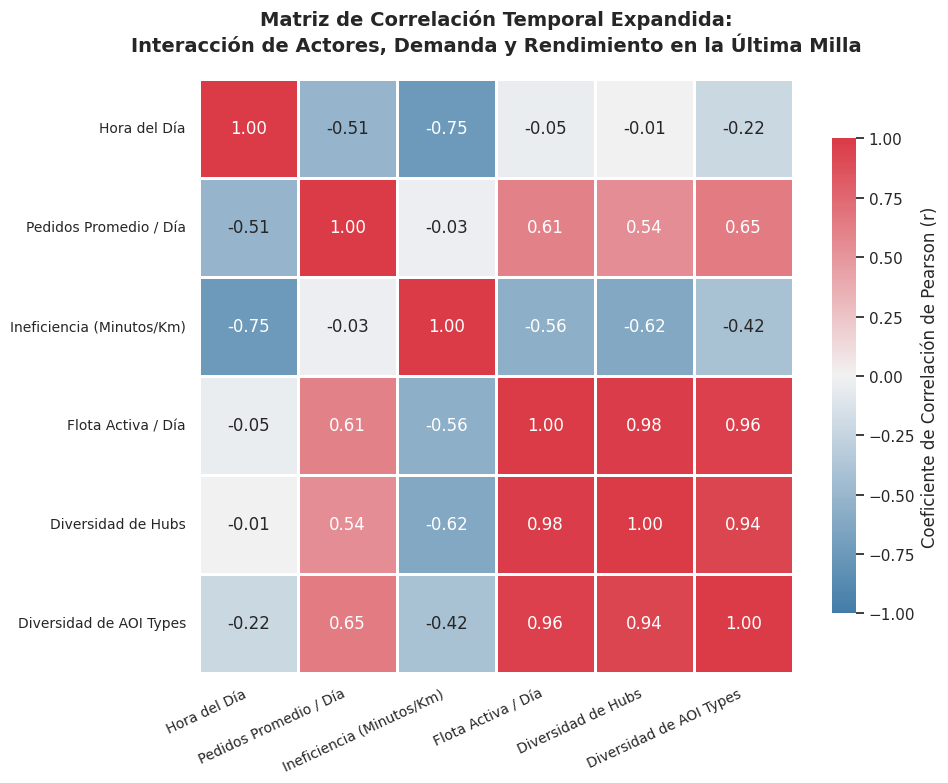

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aseguramos que las métricas y columnas clave estén en df4
df4["ratio_minkm"] = df["ratio_minkm"]

# Nos aseguramos de que los IDs y categorías se traten como texto antes de agrupar
for col in ["courier_id", "hub_id", "aoi_type"]:
    if col in df4.columns:
        df4[col] = df4[col].astype(str)

# 2. Obtenemos el total de días únicos para normalizar el volumen
total_dias_operacion = df4["ds"].nunique()

# 3. Agrupamos por hora calculando el volumen, rendimiento y la diversidad de actores
df_perfil_avanzado = (
    df4.groupby("accept_hour")
    .agg(
        pedidos_totales=("order_id", "count"),
        eficiencia_minkm=(
            "ratio_minkm",
            lambda x: x.mean() / 60,
        ),  # Convertido a minutos/km
        remitentes_unicos=("hub_id", "nunique"),  # Variedad de centros de despacho
        destinos_unicos=(
            "aoi_type",
            "nunique",
        ),  # Variedad de tipos de zona (comercial, residencial, etc.)
        repartidores_activos=(
            "courier_id",
            "nunique",
        ),  # Densidad de la flota por hora
    )
    .reset_index()
)

# Estandarizamos las métricas por día para que tengan coherencia de negocio
df_perfil_avanzado["Pedidos Promedio / Día"] = (
    df_perfil_avanzado["pedidos_totales"] / total_dias_operacion
)
df_perfil_avanzado["Flota Activa / Día"] = (
    df_perfil_avanzado["repartidores_activos"] / total_dias_operacion
)

# 4. Seleccionamos y renombramos las variables para el Heatmap final
df_analisis_kpi = df_perfil_avanzado[
    [
        "accept_hour",
        "Pedidos Promedio / Día",
        "eficiencia_minkm",
        "Flota Activa / Día",
        "remitentes_unicos",
        "destinos_unicos",
    ]
].rename(
    columns={
        "accept_hour": "Hora del Día",
        "eficiencia_minkm": "Ineficiencia (Minutos/Km)",
        "remitentes_unicos": "Diversidad de Hubs",
        "destinos_unicos": "Diversidad de AOI Types",
    }
)

# 5. Calculamos la matriz de correlación lineal
matriz_avanzada = df_analisis_kpi.corr()

# 6. Graficamos el Heatmap ampliado
plt.figure(figsize=(10, 8))
sns.set_theme(style="white")

cmap_divergente = sns.diverging_palette(240, 10, as_cmap=True)

sns.heatmap(
    matriz_avanzada,
    annot=True,
    cmap=cmap_divergente,
    fmt=".2f",
    linewidths=1,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"label": "Coeficiente de Correlación de Pearson (r)", "shrink": 0.8},
)

plt.title(
    "Matriz de Correlación Temporal Expandida:\nInteracción de Actores, Demanda y Rendimiento en la Última Milla",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xticks(rotation=25, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()